<a href="https://colab.research.google.com/github/aranavkumar/Veloura/blob/main/10_Veloura_Explainability_Evidence_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# PHASE 10 — CELL 1: EXPLAINABILITY AGENT INITIALIZATION
# ============================================================

import os
import json
import pandas as pd
import numpy as np
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. LOCATE VELOURA PROJECT
# ------------------------------------------------------------

PROJECT_CANDIDATES = [
    "/content/drive_phase9/MyDrive/Veloura_Project",
    "/content/drive_phase8/MyDrive/Veloura_Project",
    "/content/drive/MyDrive/Veloura_Project"
]

PROJECT_DIR = next(
    (
        path for path in PROJECT_CANDIDATES
        if os.path.isdir(path)
    ),
    None
)

if PROJECT_DIR is None:
    from google.colab import drive
    drive.mount("/content/drive_phase10")

    PROJECT_DIR = (
        "/content/drive_phase10/MyDrive/Veloura_Project"
    )

assert os.path.isdir(PROJECT_DIR), (
    "Veloura project directory not found."
)

print("PROJECT DIRECTORY:", PROJECT_DIR)


# ------------------------------------------------------------
# 2. DEFINE UPSTREAM INPUT FILES
# ------------------------------------------------------------

INPUT_FILES = {

    "lesion_analysis": os.path.join(
        PROJECT_DIR,
        "outputs",
        "agent_logs",
        "lesion_analysis_sample_logs.json"
    ),

    "reasoning_context": os.path.join(
        PROJECT_DIR,
        "outputs",
        "reasoning_context",
        "reasoning_context_sample_logs.json"
    ),

    "safety_agent": os.path.join(
        PROJECT_DIR,
        "outputs",
        "safety_agent",
        "safety_agent_sample_logs.json"
    ),

    "safety_coordinator": os.path.join(
        PROJECT_DIR,
        "outputs",
        "safety_agent",
        "coordinator_integration_sample_logs.json"
    ),

    "master_coordinator": os.path.join(
        PROJECT_DIR,
        "outputs",
        "master_coordinator",
        "master_coordinator_sample_logs.json"
    ),

    "evaluation_details": os.path.join(
        PROJECT_DIR,
        "outputs",
        "evaluation_performance",
        "evaluation_performance_sample_logs.json"
    ),

    "evaluation_aggregate": os.path.join(
        PROJECT_DIR,
        "outputs",
        "evaluation_performance",
        "evaluation_aggregate_report.json"
    )
}


# ------------------------------------------------------------
# 3. VERIFY UPSTREAM FILES
# ------------------------------------------------------------

print("\nUPSTREAM FILE VERIFICATION")
print("=" * 75)

for name, path in INPUT_FILES.items():

    exists = os.path.isfile(path)

    print(
        f"[{'FOUND' if exists else 'MISSING'}] "
        f"{name}: {os.path.basename(path)}"
    )

assert all(
    os.path.isfile(path)
    for path in INPUT_FILES.values()
), "One or more upstream files are missing."


# ------------------------------------------------------------
# 4. LOAD ALL UPSTREAM DATA
# ------------------------------------------------------------

explainability_inputs = {}

for name, path in INPUT_FILES.items():

    with open(path, "r") as file:
        explainability_inputs[name] = json.load(file)

    data = explainability_inputs[name]

    if isinstance(data, list):
        print(f"{name}: {len(data)} records")
    else:
        print(f"{name}: aggregate report loaded")


# ------------------------------------------------------------
# 5. CREATE IMAGE-BASED LOOKUPS
# ------------------------------------------------------------

LIST_INPUTS = [
    "lesion_analysis",
    "reasoning_context",
    "safety_agent",
    "safety_coordinator",
    "master_coordinator",
    "evaluation_details"
]

explainability_lookups = {
    name: {
        record["image_id"]: record
        for record in explainability_inputs[name]
    }
    for name in LIST_INPUTS
}

reference_ids = set(
    explainability_lookups[
        "lesion_analysis"
    ].keys()
)

assert all(
    set(explainability_lookups[name].keys())
    == reference_ids
    for name in LIST_INPUTS
), "Image IDs do not match across upstream agents."

print("\nUnique images:", len(reference_ids))
print("Image IDs:", sorted(reference_ids))


# ------------------------------------------------------------
# 6. INSPECT LESION EVIDENCE STRUCTURE
# ------------------------------------------------------------

sample_id = sorted(reference_ids)[0]

sample_lesion = explainability_lookups[
    "lesion_analysis"
][sample_id]

print("\nLESION ANALYSIS FIELD INSPECTION")
print("=" * 75)

print("Top-level fields:", list(sample_lesion.keys()))

for key, value in sample_lesion.items():

    if isinstance(value, dict):
        print(f"{key}: dictionary fields = {list(value.keys())}")

    elif isinstance(value, list):
        print(f"{key}: list with {len(value)} items")

    else:
        print(f"{key}: {value}")


# ------------------------------------------------------------
# 7. CREATE OUTPUT DIRECTORIES
# ------------------------------------------------------------

EXPLAINABILITY_OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "outputs",
    "explainability_evidence"
)

EXPLAINABILITY_REPORT_DIR = os.path.join(
    PROJECT_DIR,
    "reports",
    "explainability_evidence"
)

os.makedirs(
    EXPLAINABILITY_OUTPUT_DIR,
    exist_ok=True
)

os.makedirs(
    EXPLAINABILITY_REPORT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# 8. INITIALIZATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("VELOURA EXPLAINABILITY & EVIDENCE AGENT")
print("=" * 75)

print("Upstream components:", len(LIST_INPUTS))
print("Total sample images:", len(reference_ids))

print(
    "Output directory:",
    EXPLAINABILITY_OUTPUT_DIR
)

print(
    "Report directory:",
    EXPLAINABILITY_REPORT_DIR
)

print("\nSUCCESS: PHASE 10 INITIALIZED!")

Mounted at /content/drive_phase10
PROJECT DIRECTORY: /content/drive_phase10/MyDrive/Veloura_Project

UPSTREAM FILE VERIFICATION
[FOUND] lesion_analysis: lesion_analysis_sample_logs.json
[FOUND] reasoning_context: reasoning_context_sample_logs.json
[FOUND] safety_agent: safety_agent_sample_logs.json
[FOUND] safety_coordinator: coordinator_integration_sample_logs.json
[FOUND] master_coordinator: master_coordinator_sample_logs.json
[FOUND] evaluation_details: evaluation_performance_sample_logs.json
[FOUND] evaluation_aggregate: evaluation_aggregate_report.json
lesion_analysis: 6 records
reasoning_context: 6 records
safety_agent: 6 records
safety_coordinator: 6 records
master_coordinator: 6 records
evaluation_details: 6 records
evaluation_aggregate: aggregate report loaded

Unique images: 6
Image IDs: ['ISIC_0025481', 'ISIC_0028145', 'ISIC_0031157', 'ISIC_0031437', 'ISIC_0033038', 'ISIC_0034119']

LESION ANALYSIS FIELD INSPECTION
Top-level fields: ['agent', 'image_id', 'status', 'segmentat

In [ ]:
# ============================================================
# PHASE 10 — CELL 2: EXPLAINABILITY & EVIDENCE ENGINE
# ============================================================

import json
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. DEFINE EXPLANATION DICTIONARIES
# ------------------------------------------------------------

SAFETY_EXPLANATIONS = {

    "MISSING_PATIENT_CONTEXT": (
        "Patient information is incomplete. "
        "Age, sex, and lesion location were not supplied."
    ),

    "EXPERIMENTAL_FEATURES": (
        "Image-derived features are experimental "
        "and have not been clinically validated."
    ),

    "UNVALIDATED_SEGMENTATION": (
        "The segmentation has not been validated "
        "against expert reference masks."
    ),

    "MANDATORY_HUMAN_REVIEW": (
        "The upstream analysis explicitly requires "
        "qualified human review."
    ),

    "AUTOMATIC_ACCEPTANCE_RESTRICTION": (
        "Automatic case acceptance is not permitted."
    ),

    "DIAGNOSTIC_AUTHORITY_RESTRICTION": (
        "The system is not authorized to independently "
        "diagnose the lesion."
    )
}


# ------------------------------------------------------------
# 2. SAFE VALUE FORMATTER
# ------------------------------------------------------------

def explain_value(value):

    if value is None:
        return "NOT_AVAILABLE"

    if isinstance(value, float):
        return round(value, 6)

    if isinstance(value, dict):
        return {
            key: explain_value(val)
            for key, val in value.items()
        }

    if isinstance(value, list):
        return [
            explain_value(item)
            for item in value
        ]

    return value


# ------------------------------------------------------------
# 3. GENERATE EXPLANATION FOR ONE CASE
# ------------------------------------------------------------

def generate_case_explanation(image_id):

    lesion = explainability_lookups[
        "lesion_analysis"
    ][image_id]

    context = explainability_lookups[
        "reasoning_context"
    ][image_id]

    safety = explainability_lookups[
        "safety_agent"
    ][image_id]

    safety_coord = explainability_lookups[
        "safety_coordinator"
    ][image_id]

    master = explainability_lookups[
        "master_coordinator"
    ][image_id]

    evaluation = explainability_lookups[
        "evaluation_details"
    ][image_id]

    # --------------------------------------------------------
    # A. SEGMENTATION EVIDENCE
    # --------------------------------------------------------

    segmentation = lesion.get(
        "segmentation", {}
    )

    segmentation_evidence = {
        "method": lesion.get(
            "segmentation_method",
            "NOT_REPORTED"
        ),

        "status": segmentation.get(
            "status",
            "NOT_REPORTED"
        ),

        "area_pixels": explain_value(
            segmentation.get("area_pixels")
        ),

        "area_fraction": explain_value(
            segmentation.get("area_fraction")
        ),

        "reason": segmentation.get(
            "reason"
        ),

        "validation_status": (
            "NOT_VALIDATED_AGAINST_EXPERT_MASKS"
        )
    }

    # --------------------------------------------------------
    # B. EXPERIMENTAL FEATURE EVIDENCE
    # --------------------------------------------------------

    features = lesion.get("features", {})

    feature_names = [
        "asymmetry_estimate",
        "boundary_irregularity_estimate",
        "circularity_estimate",
        "colour_variation"
    ]

    feature_evidence = {
        name: explain_value(features.get(name))
        for name in feature_names
    }

    feature_explanation = {
        "feature_status": features.get(
            "feature_status",
            "NOT_REPORTED"
        ),

        "measurements": feature_evidence,

        "reliability": explain_value(
            features.get("segmentation_reliability")
        ),

        "interpretation": (
            "These values are experimental image-derived "
            "measurements. They must not be interpreted "
            "as validated diagnostic indicators."
        )
    }

    # --------------------------------------------------------
    # C. PATIENT AND LESION CONTEXT
    # --------------------------------------------------------

    patient_context = context.get(
        "patient_context", {}
    )

    lesion_context = context.get(
        "lesion_context", {}
    )

    missing_information = context.get(
        "missing_information", []
    )

    context_explanation = {
        "age": patient_context.get("age"),
        "sex": patient_context.get("sex"),

        "lesion_location": lesion_context.get(
            "location"
        ),

        "missing_information": missing_information,

        "completeness_status": context.get(
            "context_completeness", {}
        ).get("status"),

        "completeness_score": context.get(
            "context_completeness", {}
        ).get("score"),

        "score_interpretation": (
            "DATA_AVAILABILITY_ONLY"
        )
    }

    # --------------------------------------------------------
    # D. SAFETY FLAG EXPLANATIONS
    # --------------------------------------------------------

    observed_flags = safety.get(
        "safety_flags", []
    )

    safety_explanations = []

    for flag in observed_flags:

        safety_explanations.append({
            "flag": flag,

            "explanation": SAFETY_EXPLANATIONS.get(
                flag,
                "Safety restriction identified by the "
                "upstream safety agent."
            ),

            "source": "Veloura Safety Agent"
        })

    # --------------------------------------------------------
    # E. EXPLAIN COORDINATOR DECISION
    # --------------------------------------------------------

    decision_explanation = [

        "The lesion analysis is marked REVIEW_REQUIRED.",

        "Patient context is incomplete or insufficient.",

        "Image-derived features remain experimental.",

        "Segmentation has not been validated against "
        "expert reference masks.",

        "The Safety Agent requires qualified human review.",

        "The Master Coordinator therefore blocks "
        "automated progression."
    ]

    # --------------------------------------------------------
    # F. EVIDENCE PROVENANCE
    # --------------------------------------------------------

    provenance = [

        {
            "source_agent": "Veloura Lesion Analysis Agent",
            "source_record": "Phase 5",
            "evidence": [
                "Segmentation metadata",
                "Experimental feature measurements",
                "Analysis status",
                "Source warnings"
            ]
        },

        {
            "source_agent": "Veloura Reasoning & Context Agent",
            "source_record": "Phase 6",
            "evidence": [
                "Patient context",
                "Lesion context",
                "Missing information",
                "Context completeness"
            ]
        },

        {
            "source_agent": "Veloura Safety Agent",
            "source_record": "Phase 7",
            "evidence": [
                "Safety flags",
                "Safety decision",
                "Clinical safeguards"
            ]
        },

        {
            "source_agent": "Veloura Coordinator",
            "source_record": "Phase 7",
            "evidence": [
                "Safety gate",
                "Clinician escalation",
                "Workflow restrictions"
            ]
        },

        {
            "source_agent": "Veloura Master Coordinator",
            "source_record": "Phase 8",
            "evidence": [
                "Unified workflow status",
                "Agent availability",
                "Final workflow action"
            ]
        },

        {
            "source_agent": "Veloura Evaluation & Performance Agent",
            "source_record": "Phase 9",
            "evidence": [
                "Technical checks",
                "Clinical validation status",
                "Metric availability"
            ]
        }
    ]

    # --------------------------------------------------------
    # G. BUILD FINAL EXPLANATION RECORD
    # --------------------------------------------------------

    explanation_record = {

        "image_id": image_id,

        "agent": "Veloura Explainability & Evidence Agent",

        "generated_at": datetime.now(
            timezone.utc
        ).isoformat(),

        "explanation_status": "GENERATED",

        "analysis_evidence": {
            "analysis_status": lesion.get("status"),
            "segmentation": segmentation_evidence,
            "features": feature_explanation
        },

        "patient_and_lesion_context": (
            context_explanation
        ),

        "safety_explanation": {
            "decision": safety.get(
                "safety_decision"
            ),

            "flags": safety_explanations,

            "human_review_required": True
        },

        "coordinator_explanation": {
            "workflow_status": master.get(
                "orchestration_status"
            ),

            "coordinator_action": master.get(
                "coordinator_action"
            ),

            "safety_gate_passed": safety_coord.get(
                "safety_gate", {}
            ).get("passed"),

            "decision_reasons": decision_explanation
        },

        "evaluation_evidence": {
            "technical_checks_passed": evaluation.get(
                "technical_evaluation", {}
            ).get("checks_passed"),

            "technical_checks_total": evaluation.get(
                "technical_evaluation", {}
            ).get("total_checks"),

            "clinical_validation_status": evaluation.get(
                "clinical_validation_status"
            )
        },

        "evidence_provenance": provenance,

        "clinical_limitations": [
            "No independent diagnosis is generated.",
            "Experimental features are not clinically validated.",
            "Segmentation is not validated against expert masks.",
            "Clinical performance metrics are unavailable.",
            "Human clinician review remains mandatory."
        ],

        "final_explanation": (
            "This case requires qualified clinician review "
            "because the analysis remains experimental, "
            "patient context is incomplete, and the safety "
            "workflow explicitly blocks automated clearance. "
            "This explanation is a workflow and evidence "
            "summary, not a medical diagnosis."
        )
    }

    return explanation_record


# ------------------------------------------------------------
# 4. GENERATE ALL SIX EXPLANATIONS
# ------------------------------------------------------------

explainability_results = [

    generate_case_explanation(image_id)

    for image_id in sorted(reference_ids)

]


# ------------------------------------------------------------
# 5. DISPLAY EXPLANATION PREVIEW
# ------------------------------------------------------------

print("=" * 75)
print("VELOURA EXPLAINABILITY & EVIDENCE ENGINE")
print("=" * 75)

for record in explainability_results:

    print("\nIMAGE:", record["image_id"])

    print(
        "Explanation status:",
        record["explanation_status"]
    )

    print(
        "Analysis status:",
        record["analysis_evidence"]["analysis_status"]
    )

    print(
        "Segmentation method:",
        record["analysis_evidence"][
            "segmentation"
        ]["method"]
    )

    print(
        "Experimental features:",
        record["analysis_evidence"][
            "features"
        ]["feature_status"]
    )

    print(
        "Missing information:",
        record["patient_and_lesion_context"][
            "missing_information"
        ]
    )

    print(
        "Safety flags explained:",
        len(record["safety_explanation"]["flags"])
    )

    print(
        "Workflow:",
        record["coordinator_explanation"][
            "workflow_status"
        ]
    )

    print(
        "Decision:",
        record["coordinator_explanation"][
            "coordinator_action"
        ]
    )

print("\nTotal explanations generated:", len(explainability_results))

print("\nSUCCESS: EXPLAINABILITY ENGINE EXECUTED!")

VELOURA EXPLAINABILITY & EVIDENCE ENGINE

IMAGE: ISIC_0025481
Explanation status: GENERATED
Analysis status: REVIEW_REQUIRED
Segmentation method: GRABCUT_V1
Experimental features: EXPERIMENTAL_UNVALIDATED
Missing information: ['age', 'sex', 'lesion_location']
Safety flags explained: 4
Workflow: BLOCKED_PENDING_HUMAN_REVIEW
Decision: ESCALATE_TO_CLINICIAN

IMAGE: ISIC_0028145
Explanation status: GENERATED
Analysis status: REVIEW_REQUIRED
Segmentation method: GRABCUT_V1
Experimental features: EXPERIMENTAL_UNVALIDATED
Missing information: ['age', 'sex', 'lesion_location']
Safety flags explained: 4
Workflow: BLOCKED_PENDING_HUMAN_REVIEW
Decision: ESCALATE_TO_CLINICIAN

IMAGE: ISIC_0031157
Explanation status: GENERATED
Analysis status: REVIEW_REQUIRED
Segmentation method: GRABCUT_V1
Experimental features: EXPERIMENTAL_UNVALIDATED
Missing information: ['age', 'sex', 'lesion_location']
Safety flags explained: 4
Workflow: BLOCKED_PENDING_HUMAN_REVIEW
Decision: ESCALATE_TO_CLINICIAN

IMAGE: ISI

In [ ]:
# ============================================================
# PHASE 10 — CELL 3: CLINICIAN SUMMARIES & EVIDENCE EXPORT
# ============================================================

import os
import json
import pandas as pd
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. CREATE CLINICIAN-READABLE SUMMARIES
# ------------------------------------------------------------

clinician_summaries = []

for record in explainability_results:

    image_id = record["image_id"]

    analysis = record["analysis_evidence"]
    segmentation = analysis["segmentation"]
    features = analysis["features"]

    context = record["patient_and_lesion_context"]
    safety = record["safety_explanation"]
    coordinator = record["coordinator_explanation"]
    evaluation = record["evaluation_evidence"]

    summary = {

        "image_id": image_id,

        "report_title": (
            "Veloura — Explainable Evidence Summary"
        ),

        "analysis_overview": {
            "analysis_status": analysis["analysis_status"],
            "segmentation_method": segmentation["method"],
            "segmentation_status": segmentation["status"],
            "segmentation_area_fraction": (
                segmentation["area_fraction"]
            )
        },

        "experimental_feature_overview": {
            "feature_status": features["feature_status"],
            "measurements": features["measurements"],
            "interpretation": features["interpretation"]
        },

        "patient_context_overview": {
            "age": context["age"],
            "sex": context["sex"],
            "lesion_location": context["lesion_location"],
            "missing_information": context[
                "missing_information"
            ],
            "completeness_status": context[
                "completeness_status"
            ]
        },

        "safety_review": {
            "decision": safety["decision"],
            "flags": [
                item["flag"]
                for item in safety["flags"]
            ],
            "human_review_required": (
                safety["human_review_required"]
            )
        },

        "coordinator_decision": {
            "workflow_status": coordinator[
                "workflow_status"
            ],
            "action": coordinator[
                "coordinator_action"
            ],
            "safety_gate_passed": coordinator[
                "safety_gate_passed"
            ]
        },

        "evaluation_status": {
            "technical_checks_passed": evaluation[
                "technical_checks_passed"
            ],
            "technical_checks_total": evaluation[
                "technical_checks_total"
            ],
            "clinical_validation": evaluation[
                "clinical_validation_status"
            ]
        },

        "clinician_review_note": (
            "Review the original dermoscopic image and "
            "clinical history. The segmentation and "
            "image-derived features are experimental. "
            "No diagnosis or treatment recommendation "
            "is generated by Veloura."
        ),

        "final_summary": record["final_explanation"],

        "generated_at": datetime.now(
            timezone.utc
        ).isoformat()
    }

    clinician_summaries.append(summary)


# ------------------------------------------------------------
# 2. BUILD EVIDENCE TRACEABILITY MATRIX
# ------------------------------------------------------------

traceability_rows = []

for record in explainability_results:

    image_id = record["image_id"]

    for source in record["evidence_provenance"]:

        traceability_rows.append({

            "image_id": image_id,

            "source_agent": source["source_agent"],

            "source_phase": source["source_record"],

            "evidence_items": " | ".join(
                source["evidence"]
            ),

            "source_record_available": (
                image_id in reference_ids
            )
        })

traceability_df = pd.DataFrame(
    traceability_rows
)


# ------------------------------------------------------------
# 3. BUILD CLINICIAN SUMMARY TABLE
# ------------------------------------------------------------

clinician_summary_df = pd.DataFrame([

    {
        "image_id": record["image_id"],

        "analysis_status": record[
            "analysis_overview"
        ]["analysis_status"],

        "segmentation_method": record[
            "analysis_overview"
        ]["segmentation_method"],

        "feature_status": record[
            "experimental_feature_overview"
        ]["feature_status"],

        "missing_information": " | ".join(
            record["patient_context_overview"][
                "missing_information"
            ]
        ),

        "safety_decision": record[
            "safety_review"
        ]["decision"],

        "workflow_status": record[
            "coordinator_decision"
        ]["workflow_status"],

        "clinician_review_required": record[
            "safety_review"
        ]["human_review_required"],

        "clinical_validation": record[
            "evaluation_status"
        ]["clinical_validation"]

    }

    for record in clinician_summaries

])


# ------------------------------------------------------------
# 4. EXPORT EXPLAINABILITY JSON
# ------------------------------------------------------------

EXPLANATION_JSON = os.path.join(
    EXPLAINABILITY_OUTPUT_DIR,
    "explainability_evidence_sample_logs.json"
)

CLINICIAN_JSON = os.path.join(
    EXPLAINABILITY_OUTPUT_DIR,
    "clinician_readable_case_summaries.json"
)

with open(EXPLANATION_JSON, "w") as file:
    json.dump(
        explainability_results,
        file,
        indent=4
    )

with open(CLINICIAN_JSON, "w") as file:
    json.dump(
        clinician_summaries,
        file,
        indent=4
    )


# ------------------------------------------------------------
# 5. EXPORT CSV REPORTS
# ------------------------------------------------------------

CLINICIAN_CSV = os.path.join(
    EXPLAINABILITY_REPORT_DIR,
    "clinician_case_summary.csv"
)

TRACEABILITY_CSV = os.path.join(
    EXPLAINABILITY_REPORT_DIR,
    "evidence_traceability_matrix.csv"
)

clinician_summary_df.to_csv(
    CLINICIAN_CSV,
    index=False
)

traceability_df.to_csv(
    TRACEABILITY_CSV,
    index=False
)


# ------------------------------------------------------------
# 6. RELOAD EXPORTED FILES
# ------------------------------------------------------------

with open(EXPLANATION_JSON, "r") as file:
    exported_explanations = json.load(file)

with open(CLINICIAN_JSON, "r") as file:
    exported_summaries = json.load(file)

reloaded_clinician = pd.read_csv(
    CLINICIAN_CSV
)

reloaded_traceability = pd.read_csv(
    TRACEABILITY_CSV
)


# ------------------------------------------------------------
# 7. EVIDENCE TRACEABILITY TESTS
# ------------------------------------------------------------

tests = {

    "Six explanation records exported":
        len(exported_explanations) == 6,

    "Six clinician summaries exported":
        len(exported_summaries) == 6,

    "Six clinician summary CSV rows":
        len(reloaded_clinician) == 6,

    "Thirty-six provenance records":
        len(reloaded_traceability) == 36,

    "All image IDs preserved":
        {
            record["image_id"]
            for record in exported_explanations
        } == reference_ids,

    "All cases contain segmentation evidence":
        all(
            record["analysis_evidence"]["segmentation"][
                "method"
            ] == "GRABCUT_V1"
            for record in exported_explanations
        ),

    "All cases preserve experimental feature status":
        all(
            record["analysis_evidence"]["features"][
                "feature_status"
            ] == "EXPERIMENTAL_UNVALIDATED"
            for record in exported_explanations
        ),

    "All cases explain four safety flags":
        all(
            len(record["safety_explanation"]["flags"]) == 4
            for record in exported_explanations
        ),

    "All cases preserve missing context":
        all(
            set(["age", "sex", "lesion_location"]).issubset(
                set(record["patient_and_lesion_context"][
                    "missing_information"
                ])
            )
            for record in exported_explanations
        ),

    "All cases require clinician review":
        all(
            record["safety_explanation"][
                "human_review_required"
            ] is True
            for record in exported_explanations
        ),

    "All cases preserve coordinator decisions":
        all(
            record["coordinator_explanation"][
                "coordinator_action"
            ] == "ESCALATE_TO_CLINICIAN"
            for record in exported_explanations
        ),

    "All cases preserve clinical limitations":
        all(
            record["clinical_limitations"]
            for record in exported_explanations
        ),

    "All provenance sources represented":
        all(
            len(record["evidence_provenance"]) == 6
            for record in exported_explanations
        ),

    "Clinical summaries preserve non-diagnostic wording":
        all(
            "No diagnosis" in record["clinician_review_note"]
            for record in exported_summaries
        )
}


# ------------------------------------------------------------
# 8. DISPLAY FINAL REPORT
# ------------------------------------------------------------

print("=" * 75)
print("VELOURA PHASE 10 — EVIDENCE & SUMMARY REPORT")
print("=" * 75)

print("\nCLINICIAN SUMMARY")
print(
    clinician_summary_df.to_string(index=False)
)

print("\nEVIDENCE TRACEABILITY")
print("Total provenance records:", len(traceability_df))

print(
    "Unique source agents:",
    traceability_df["source_agent"].nunique()
)

print("\n" + "=" * 75)
print("PHASE 10 FINAL VERIFICATION")
print("=" * 75)

for name, passed in tests.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

print(
    "\nVerification:",
    sum(tests.values()),
    "/",
    len(tests)
)

print("\nEXPORTED FILES")

for path in [
    EXPLANATION_JSON,
    CLINICIAN_JSON,
    CLINICIAN_CSV,
    TRACEABILITY_CSV
]:

    print(path)

if all(tests.values()):

    print("\nSUCCESS: PHASE 10 COMPLETED AND VERIFIED!")

else:

    print("\nWARNING: SOME VERIFICATION TESTS FAILED.")

VELOURA PHASE 10 — EVIDENCE & SUMMARY REPORT

CLINICIAN SUMMARY
    image_id analysis_status segmentation_method           feature_status         missing_information       safety_decision              workflow_status  clinician_review_required      clinical_validation
ISIC_0025481 REVIEW_REQUIRED          GRABCUT_V1 EXPERIMENTAL_UNVALIDATED age | sex | lesion_location HUMAN_REVIEW_REQUIRED BLOCKED_PENDING_HUMAN_REVIEW                       True NOT_CLINICALLY_VALIDATED
ISIC_0028145 REVIEW_REQUIRED          GRABCUT_V1 EXPERIMENTAL_UNVALIDATED age | sex | lesion_location HUMAN_REVIEW_REQUIRED BLOCKED_PENDING_HUMAN_REVIEW                       True NOT_CLINICALLY_VALIDATED
ISIC_0031157 REVIEW_REQUIRED          GRABCUT_V1 EXPERIMENTAL_UNVALIDATED age | sex | lesion_location HUMAN_REVIEW_REQUIRED BLOCKED_PENDING_HUMAN_REVIEW                       True NOT_CLINICALLY_VALIDATED
ISIC_0031437 REVIEW_REQUIRED          GRABCUT_V1 EXPERIMENTAL_UNVALIDATED age | sex | lesion_location HUMAN_REVIEW_R

In [ ]:
# ============================================================
# PHASE 10 — CELL 4: IMAGE & MASK ASSET AUDIT
# ============================================================

import os
import json

# ------------------------------------------------------------
# 1. FIND IMAGE AND MASK FILES
# ------------------------------------------------------------

IMAGE_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
)

image_files = []
mask_files = []

for root, dirs, files in os.walk(PROJECT_DIR):

    # Avoid unnecessary notebook/cache directories
    dirs[:] = [
        d for d in dirs
        if d not in {".ipynb_checkpoints", "__pycache__"}
    ]

    for filename in files:

        lower_name = filename.lower()
        full_path = os.path.join(root, filename)

        if lower_name.endswith(IMAGE_EXTENSIONS):

            if any(
                term in lower_name
                for term in ["mask", "segmentation", "ground_truth"]
            ):
                mask_files.append(full_path)
            else:
                image_files.append(full_path)


# ------------------------------------------------------------
# 2. FIND IMAGE AND MASK REFERENCES IN LESION RECORDS
# ------------------------------------------------------------

def find_asset_references(data, prefix=""):

    references = []

    if isinstance(data, dict):

        for key, value in data.items():

            current = f"{prefix}.{key}" if prefix else key

            if any(
                term in key.lower()
                for term in [
                    "image_path", "image_file",
                    "mask_path", "mask_file",
                    "segmentation_path",
                    "overlay_path"
                ]
            ):
                references.append({
                    "field": current,
                    "value": value
                })

            references.extend(
                find_asset_references(value, current)
            )

    elif isinstance(data, list):

        for index, item in enumerate(data):

            references.extend(
                find_asset_references(
                    item, f"{prefix}[{index}]"
                )
            )

    return references


asset_references = []

for image_id, record in explainability_lookups[
    "lesion_analysis"
].items():

    refs = find_asset_references(record)

    for ref in refs:

        asset_references.append({
            "image_id": image_id,
            **ref
        })


# ------------------------------------------------------------
# 3. CHECK SEGMENTATION DATA STRUCTURE
# ------------------------------------------------------------

print("=" * 75)
print("VELOURA IMAGE & SEGMENTATION ASSET AUDIT")
print("=" * 75)

print("\nIMAGE FILES FOUND:", len(image_files))
print("MASK FILES FOUND:", len(mask_files))

print("\nIMAGE FILE SAMPLE")

for path in image_files[:15]:
    print(path)

print("\nMASK FILE SAMPLE")

for path in mask_files[:15]:
    print(path)


# ------------------------------------------------------------
# 4. DISPLAY STORED ASSET REFERENCES
# ------------------------------------------------------------

print("\nSTORED IMAGE/MASK REFERENCES")
print("=" * 75)

if asset_references:

    for ref in asset_references:
        print(ref)

else:

    print("No explicit image or mask paths found in lesion records.")


# ------------------------------------------------------------
# 5. INSPECT SEGMENTATION OBJECTS
# ------------------------------------------------------------

print("\nSEGMENTATION DATA INSPECTION")
print("=" * 75)

for image_id in sorted(reference_ids):

    segmentation = explainability_lookups[
        "lesion_analysis"
    ][image_id].get("segmentation", {})

    print("\nIMAGE:", image_id)
    print("Fields:", list(segmentation.keys()))
    print("Data:", segmentation)


# ------------------------------------------------------------
# 6. AUDIT SUMMARY
# ------------------------------------------------------------

audit_summary = {
    "image_files_found": len(image_files),
    "mask_files_found": len(mask_files),
    "stored_asset_references": len(asset_references),
    "segmentation_records_inspected": len(reference_ids),
    "visual_overlay_readiness": (
        "REQUIRES_ASSET_VALIDATION"
    )
}

print("\n" + "=" * 75)
print("ASSET AUDIT SUMMARY")
print("=" * 75)

print(json.dumps(audit_summary, indent=4))

VELOURA IMAGE & SEGMENTATION ASSET AUDIT

IMAGE FILES FOUND: 9704
MASK FILES FOUND: 0

IMAGE FILE SAMPLE
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0031046.jpg
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0025353.jpg
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0024949.jpg
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0024350.jpg
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0031564.jpg
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0027922.jpg
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0032897.jpg
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training

In [ ]:
# ============================================================
# PHASE 10 — CELL 5: TARGETED IMAGE & ANNOTATION AUDIT
# ============================================================

import os
from pathlib import Path

# ------------------------------------------------------------
# 1. TARGET IMAGE IDS
# ------------------------------------------------------------

target_ids = sorted(reference_ids)

image_matches = {image_id: [] for image_id in target_ids}
annotation_files = []
annotation_directories = []

annotation_terms = [
    "mask", "segmentation", "annotation",
    "ground_truth", "groundtruth", "label",
    "contour", "lesion_boundary"
]

metadata_extensions = {
    ".csv", ".json", ".xml", ".yaml", ".yml",
    ".geojson", ".npy", ".npz", ".mat"
}

# ------------------------------------------------------------
# 2. SCAN PROJECT FILES
# ------------------------------------------------------------

for root, dirs, files in os.walk(PROJECT_DIR):

    dirs[:] = [
        d for d in dirs
        if d not in {
            ".ipynb_checkpoints",
            "__pycache__"
        }
    ]

    for directory in dirs:

        if any(
            term in directory.lower()
            for term in annotation_terms
        ):
            annotation_directories.append(
                os.path.join(root, directory)
            )

    for filename in files:

        path = os.path.join(root, filename)
        stem = Path(filename).stem.lower()
        lower_name = filename.lower()
        extension = Path(filename).suffix.lower()

        # Exact image-ID matches, irrespective of extension
        for image_id in target_ids:

            if stem == image_id.lower():
                image_matches[image_id].append(path)

        # Annotation-like files
        if (
            any(term in lower_name for term in annotation_terms)
            or extension in metadata_extensions
        ):
            annotation_files.append(path)


# ------------------------------------------------------------
# 3. REPORT EXACT IMAGE MATCHES
# ------------------------------------------------------------

print("=" * 75)
print("TARGET IMAGE MATCHES")
print("=" * 75)

for image_id, matches in image_matches.items():

    print("\nIMAGE:", image_id)
    print("Files found:", len(matches))

    for path in matches[:5]:
        print(path)


# ------------------------------------------------------------
# 4. REPORT ANNOTATION DIRECTORIES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ANNOTATION-RELATED DIRECTORIES")
print("=" * 75)

for path in sorted(set(annotation_directories))[:50]:
    print(path)

if not annotation_directories:
    print("No annotation-related directories found.")


# ------------------------------------------------------------
# 5. REPORT ANNOTATION / METADATA FILES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ANNOTATION AND METADATA FILES")
print("=" * 75)

for path in sorted(set(annotation_files))[:100]:
    print(path)

print(
    "\nTotal candidate annotation/metadata files:",
    len(set(annotation_files))
)


# ------------------------------------------------------------
# 6. FINAL AUDIT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TARGETED AUDIT SUMMARY")
print("=" * 75)

for image_id, matches in image_matches.items():

    print(
        image_id,
        "FOUND" if matches else "NOT_FOUND"
    )

print(
    "\nAnnotation directories:",
    len(set(annotation_directories))
)

print(
    "Candidate metadata files:",
    len(set(annotation_files))
)

print("\nSUCCESS: TARGETED ASSET AUDIT COMPLETED!")

TARGET IMAGE MATCHES

IMAGE: ISIC_0025481
Files found: 1
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0025481.jpg

IMAGE: ISIC_0028145
Files found: 1
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0028145.jpg

IMAGE: ISIC_0031157
Files found: 1
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0031157.jpg

IMAGE: ISIC_0031437
Files found: 1
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0031437.jpg

IMAGE: ISIC_0033038
Files found: 1
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0033038.jpg

IMAGE: ISIC_0034119
Files found: 1
/content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images/ISIC_0034119.jpg

ANNOTATION-RELATED DIRECTORIES
No annotation-related directories found.


In [ ]:

# ============================================================
# PHASE 10 — CELL 6: METADATA & SEGMENTATION-CODE AUDIT
# ============================================================

import json
import pandas as pd
from pathlib import Path

# FIX: Convert PROJECT_DIR from string to Path object
PROJECT_DIR = Path(PROJECT_DIR)

target_ids = sorted(reference_ids)
dataset_root = PROJECT_DIR / "datasets"

training_metadata = (
    dataset_root / "training/extracted/Health/training/metadata.csv"
)
evaluation_metadata = (
    dataset_root / "evaluation/extracted/Health/eval/metadata.csv"
)

# ------------------------------------------------------------
# 1. DATASET METADATA INSPECTION
# ------------------------------------------------------------

print("=" * 75)
print("1. DATASET METADATA INSPECTION")
print("=" * 75)

for metadata_path in [training_metadata, evaluation_metadata]:
    print(f"\nFILE: {metadata_path}")

    if not metadata_path.exists():
        print("NOT FOUND")
        continue

    try:
        df = pd.read_csv(metadata_path)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        id_columns = [
            col for col in df.columns
            if any(term in col.lower() for term in [
                "image", "isic", "file", "id"
            ])
        ]

        matched_rows = pd.DataFrame()

        for col in id_columns:
            values = df[col].astype(str)

            mask = values.apply(
                lambda value: any(
                    image_id in value for image_id in target_ids
                )
            )

            if mask.any():
                matched_rows = pd.concat(
                    [matched_rows, df[mask]]
                ).drop_duplicates()

        print("Potential ID columns:", id_columns)
        print("Target rows found:", len(matched_rows))

        if not matched_rows.empty:
            print(matched_rows.head(10).to_string(index=False))
        else:
            print("No target image IDs matched in candidate ID columns.")

    except Exception as e:
        print("Metadata inspection error:", repr(e))


# ------------------------------------------------------------
# 2. DATASET MANIFEST INSPECTION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("2. DATASET MANIFEST INSPECTION")
print("=" * 75)

manifest_paths = [
    dataset_root / "training/extracted/manifest.json",
    dataset_root / "evaluation/extracted/manifest.json"
]

for manifest_path in manifest_paths:
    print(f"\nFILE: {manifest_path}")

    if not manifest_path.exists():
        print("NOT FOUND")
        continue

    try:
        with open(manifest_path, "r", encoding="utf-8") as f:
            manifest = json.load(f)

        print("Top-level type:", type(manifest).__name__)

        if isinstance(manifest, dict):
            print("Top-level keys:", list(manifest.keys())[:40])

        manifest_text = json.dumps(manifest, indent=2)

        matching_lines = [
            line for line in manifest_text.splitlines()
            if any(image_id in line for image_id in target_ids)
        ]

        print("Lines mentioning target IDs:", len(matching_lines))

        for line in matching_lines[:30]:
            print(line[:300])

    except Exception as e:
        print("Manifest inspection error:", repr(e))


# ------------------------------------------------------------
# 3. PHASE 5 NOTEBOOK DISCOVERY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("3. PHASE 5 NOTEBOOK DISCOVERY")
print("=" * 75)

notebook_paths = list(PROJECT_DIR.rglob("*.ipynb"))

phase5_candidates = [
    path for path in notebook_paths
    if (
        "lesion" in path.name.lower()
        or "05_" in path.name
        or "phase5" in path.name.lower()
    )
]

print("Candidate notebooks:")

for path in phase5_candidates:
    print(path)


# ------------------------------------------------------------
# 4. ORIGINAL GRABCUT IMPLEMENTATION SEARCH
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("4. ORIGINAL GRABCUT IMPLEMENTATION SEARCH")
print("=" * 75)

search_terms = [
    "grabCut",
    "grabcut",
    "GC_INIT",
    "segmentation",
    "mask",
    "cv2.rectangle"
]

code_matches = 0

for notebook_path in phase5_candidates:
    try:
        with open(notebook_path, "r", encoding="utf-8") as f:
            notebook = json.load(f)

        print(f"\nNOTEBOOK: {notebook_path}")

        for cell_index, cell in enumerate(notebook.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))

            matching_lines = [
                line.strip()
                for line in source.splitlines()
                if any(
                    term.lower() in line.lower()
                    for term in search_terms
                )
            ]

            if matching_lines:
                code_matches += 1
                print(f"\nCode cell {cell_index}:")

                for line in matching_lines[:20]:
                    print(" ", line[:250])

    except Exception as e:
        print("Notebook inspection error:", repr(e))


# ------------------------------------------------------------
# 5. AUDIT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("AUDIT SUMMARY")
print("=" * 75)

print("Target image IDs:", len(target_ids))
print("Candidate Phase 5 notebooks:", len(phase5_candidates))
print("Code cells with segmentation-related matches:", code_matches)

print("\nSUCCESS: METADATA AND SEGMENTATION-CODE AUDIT COMPLETED!")


1. DATASET METADATA INSPECTION

FILE: /content/drive_phase10/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/metadata.csv
Shape: (7762, 6)
Columns: ['image_id', 'lesion_id', 'dx', 'age', 'sex', 'localization']
Potential ID columns: ['image_id', 'lesion_id']
Target rows found: 6
    image_id   lesion_id  dx  age    sex    localization
ISIC_0033038 HAM_0003466 mel 70.0 female lower extremity
ISIC_0034119 HAM_0003046 bcc 70.0   male            face
ISIC_0031157 HAM_0003238  nv 45.0   male           trunk
ISIC_0031437 HAM_0001376  nv 40.0   male lower extremity
ISIC_0025481 HAM_0001909  nv 55.0   male upper extremity
ISIC_0028145 HAM_0003175  nv  5.0   male lower extremity

FILE: /content/drive_phase10/MyDrive/Veloura_Project/datasets/evaluation/extracted/Health/eval/metadata.csv
Shape: (1942, 6)
Columns: ['image_id', 'lesion_id', 'dx', 'age', 'sex', 'localization']
Potential ID columns: ['image_id', 'lesion_id']
Target rows found: 0
No target image IDs matched in candi

In [ ]:

# ============================================================
# PHASE 10 — CELL 7: SOURCE-CODE RECOVERY & IMAGE INSPECTION
# ============================================================

import os
from pathlib import Path
from PIL import Image

PROJECT_DIR = Path(PROJECT_DIR)
target_ids = sorted(reference_ids)

# ------------------------------------------------------------
# 1. PROJECT STRUCTURE
# ------------------------------------------------------------

print("=" * 75)
print("1. PROJECT ROOT STRUCTURE")
print("=" * 75)

for item in sorted(PROJECT_DIR.iterdir()):
    item_type = "DIRECTORY" if item.is_dir() else "FILE"
    print(f"{item_type}: {item.name}")


# ------------------------------------------------------------
# 2. SEARCH FOR NOTEBOOKS AND SOURCE FILES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("2. NOTEBOOK AND SOURCE-FILE DISCOVERY")
print("=" * 75)

source_extensions = {".ipynb", ".py", ".md", ".txt"}
source_files = []

excluded_directories = {
    ".ipynb_checkpoints",
    "__pycache__",
    ".git"
}

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [
        directory for directory in dirs
        if directory not in excluded_directories
        and directory != "datasets"
    ]

    for filename in files:
        path = Path(root) / filename

        if path.suffix.lower() in source_extensions:
            source_files.append(path)

print("Source files discovered:", len(source_files))

for path in source_files[:100]:
    print(path)


# ------------------------------------------------------------
# 3. SEARCH SOURCE FILE CONTENT FOR GRABCUT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("3. GRABCUT SOURCE-CODE SEARCH")
print("=" * 75)

search_terms = [
    "grabCut",
    "grabcut",
    "GC_INIT_WITH_RECT",
    "GC_INIT_WITH_MASK",
    "cv2.grabCut",
    "segmentation_method"
]

source_matches = []

for path in source_files:
    try:
        # Avoid attempting to read very large source files
        if path.stat().st_size > 10 * 1024 * 1024:
            continue

        if path.suffix.lower() == ".ipynb":
            import json

            with open(path, "r", encoding="utf-8") as f:
                notebook = json.load(f)

            content = "\n".join(
                "".join(cell.get("source", []))
                for cell in notebook.get("cells", [])
            )
        else:
            content = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )

        matching_lines = [
            (line_number, line.strip())
            for line_number, line in enumerate(
                content.splitlines(), start=1
            )
            if any(
                term.lower() in line.lower()
                for term in search_terms
            )
        ]

        if matching_lines:
            source_matches.append((path, matching_lines))

    except Exception as e:
        print("Could not inspect:", path.name, repr(e))

print("Files containing segmentation-related code:", len(source_matches))

for path, matches in source_matches:
    print("\nSOURCE FILE:", path)

    for line_number, line in matches[:20]:
        print(f"Line {line_number}: {line[:250]}")


# ------------------------------------------------------------
# 4. ORIGINAL IMAGE DIMENSION AND FORMAT INSPECTION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("4. ORIGINAL IMAGE INSPECTION")
print("=" * 75)

image_root = (
    PROJECT_DIR
    / "datasets/training/extracted/Health/training/images"
)

image_inspection = []

for image_id in target_ids:
    matches = list(image_root.glob(image_id + ".*"))

    if not matches:
        print("\nIMAGE NOT FOUND:", image_id)
        continue

    image_path = matches[0]

    try:
        with Image.open(image_path) as image:
            image_inspection.append({
                "image_id": image_id,
                "path": str(image_path),
                "format": image.format,
                "mode": image.mode,
                "width": image.width,
                "height": image.height
            })

            print(
                f"\n{image_id}: "
                f"{image.width} x {image.height}, "
                f"mode={image.mode}, format={image.format}"
            )

    except Exception as e:
        print("Image inspection error:", image_id, repr(e))


# ------------------------------------------------------------
# 5. FINAL AUDIT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 7 AUDIT SUMMARY")
print("=" * 75)

print("Target images:", len(target_ids))
print("Source files discovered:", len(source_files))
print("Files with GrabCut-related code:", len(source_matches))
print("Images successfully inspected:", len(image_inspection))

if source_matches:
    print("SOURCE_CODE_STATUS: POTENTIAL_ORIGINAL_IMPLEMENTATION_FOUND")
else:
    print("SOURCE_CODE_STATUS: ORIGINAL_IMPLEMENTATION_NOT_FOUND")

print("\nSUCCESS: SOURCE AND IMAGE AUDIT COMPLETED!")


1. PROJECT ROOT STRUCTURE
FILE: README.md
DIRECTORY: datasets
DIRECTORY: documentation
DIRECTORY: models
DIRECTORY: notebooks
DIRECTORY: outputs
DIRECTORY: reports
FILE: requirements.txt

2. NOTEBOOK AND SOURCE-FILE DISCOVERY
Source files discovered: 2
/content/drive_phase10/MyDrive/Veloura_Project/README.md
/content/drive_phase10/MyDrive/Veloura_Project/requirements.txt

3. GRABCUT SOURCE-CODE SEARCH
Files containing segmentation-related code: 0

4. ORIGINAL IMAGE INSPECTION

ISIC_0025481: 600 x 450, mode=RGB, format=JPEG

ISIC_0028145: 600 x 450, mode=RGB, format=JPEG

ISIC_0031157: 600 x 450, mode=RGB, format=JPEG

ISIC_0031437: 600 x 450, mode=RGB, format=JPEG

ISIC_0033038: 600 x 450, mode=RGB, format=JPEG

ISIC_0034119: 600 x 450, mode=RGB, format=JPEG

CELL 7 AUDIT SUMMARY
Target images: 6
Source files discovered: 2
Files with GrabCut-related code: 0
Images successfully inspected: 6
SOURCE_CODE_STATUS: ORIGINAL_IMPLEMENTATION_NOT_FOUND

SUCCESS: SOURCE AND IMAGE AUDIT COMPLETED!

PHASE 10 — EXPERIMENTAL SEGMENTATION
Algorithm: OpenCV GrabCut
Initialization: Central rectangle
Iterations: 5
Random seed: 42
Expert reference masks: NOT AVAILABLE
Clinical validation: NOT PERFORMED

Processing: ISIC_0025481
Image dimensions: 600 x 450
Foreground pixels: 26755
Generated area fraction: 0.0991
Historical Phase 5 area fraction: 0.1028
Mask saved: ISIC_0025481_experimental_mask.png
Overlay saved: ISIC_0025481_experimental_overlay.png

Processing: ISIC_0028145
Image dimensions: 600 x 450
Foreground pixels: 48695
Generated area fraction: 0.1804
Historical Phase 5 area fraction: 0.2511
Mask saved: ISIC_0028145_experimental_mask.png
Overlay saved: ISIC_0028145_experimental_overlay.png

Processing: ISIC_0031157
Image dimensions: 600 x 450
Foreground pixels: 61467
Generated area fraction: 0.2277
Historical Phase 5 area fraction: 0.2613
Mask saved: ISIC_0031157_experimental_mask.png
Overlay saved: ISIC_0031157_experimental_overlay.png

Processing: ISIC_0031437
Image dimensions: 

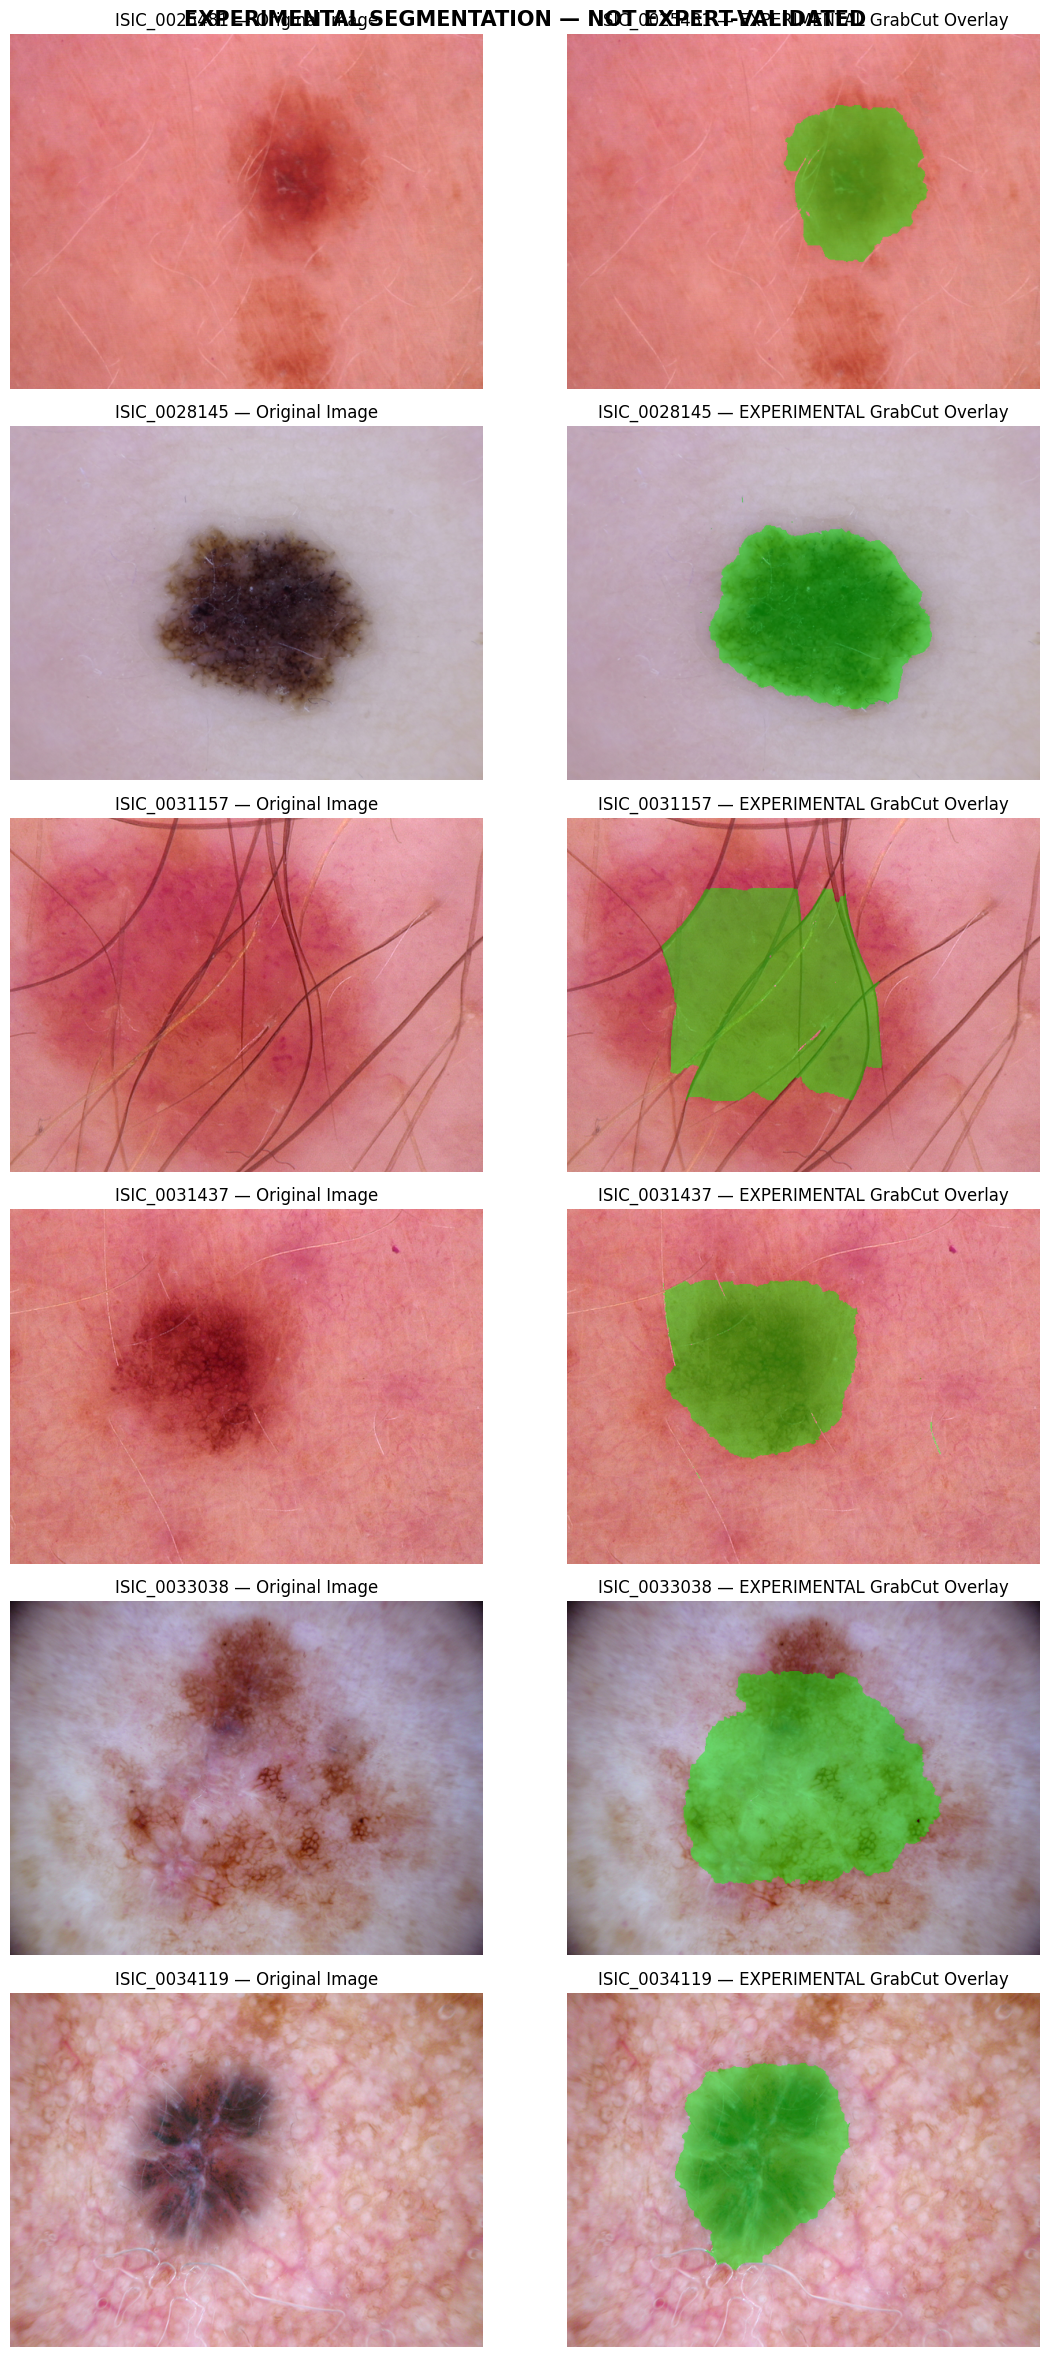


AREA FRACTION COMPARISON
ISIC_0025481 | Generated: 0.099093 | Historical: 0.1028 | Difference: -0.003707
ISIC_0028145 | Generated: 0.180352 | Historical: 0.2511 | Difference: -0.070748
ISIC_0031157 | Generated: 0.227656 | Historical: 0.2613 | Difference: -0.033644
ISIC_0031437 | Generated: 0.166444 | Historical: 0.184 | Difference: -0.017556
ISIC_0033038 | Generated: 0.247733 | Historical: 0.2912 | Difference: -0.043467
ISIC_0034119 | Generated: 0.15507 | Historical: 0.1764 | Difference: -0.02133

CELL 8 COMPLETION SUMMARY
Target images: 6
Successfully segmented: 6
Masks saved: 6
Overlays saved: 6
Expert reference masks: NOT AVAILABLE
Clinical validation: NOT PERFORMED
Automatic acceptance: DISABLED

Records file: /content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/experimental_masks/experimental_segmentation_records.json
Mask directory: /content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/experimental_masks/binary_masks
Overlay dir

In [ ]:

# ============================================================
# PHASE 10 — CELL 8:
# EXPERIMENTAL MASK GENERATION & VISUAL OVERLAYS
# ============================================================

import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path(PROJECT_DIR)

IMAGE_DIR = (
    PROJECT_DIR
    / "datasets/training/extracted/Health/training/images"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "outputs/explainability_evidence/experimental_masks"
)

MASK_DIR = OUTPUT_DIR / "binary_masks"
OVERLAY_DIR = OUTPUT_DIR / "visual_overlays"

MASK_DIR.mkdir(parents=True, exist_ok=True)
OVERLAY_DIR.mkdir(parents=True, exist_ok=True)

target_ids = sorted(reference_ids)

# Historical Phase 5 area fractions.
# These are measurements only, NOT reference masks.
phase5_area_fractions = {
    "ISIC_0025481": 0.1028,
    "ISIC_0028145": 0.2511,
    "ISIC_0031157": 0.2613,
    "ISIC_0031437": 0.1840,
    "ISIC_0033038": 0.2912,
    "ISIC_0034119": 0.1764
}

# New experimental algorithm configuration
GRABCUT_ITERATIONS = 5
RECTANGLE_WIDTH_FRACTION = 0.60
RECTANGLE_HEIGHT_FRACTION = 0.60
RANDOM_SEED = 42

cv2.setRNGSeed(RANDOM_SEED)

print("=" * 75)
print("PHASE 10 — EXPERIMENTAL SEGMENTATION")
print("=" * 75)

print("Algorithm: OpenCV GrabCut")
print("Initialization: Central rectangle")
print("Iterations:", GRABCUT_ITERATIONS)
print("Random seed:", RANDOM_SEED)
print("Expert reference masks: NOT AVAILABLE")
print("Clinical validation: NOT PERFORMED")


# ------------------------------------------------------------
# 2. PROCESS SIX ORIGINAL IMAGES
# ------------------------------------------------------------

segmentation_records = []
overlay_images = []

for image_id in target_ids:

    print("\nProcessing:", image_id)

    image_matches = list(IMAGE_DIR.glob(image_id + ".*"))

    if not image_matches:
        print("ERROR: Original image not found.")
        continue

    image_path = image_matches[0]

    try:
        # Load original image
        image_bgr = cv2.imread(str(image_path))

        if image_bgr is None:
            raise ValueError("OpenCV could not read the image.")

        height, width = image_bgr.shape[:2]

        # Central rectangle initialization
        rect_width = int(width * RECTANGLE_WIDTH_FRACTION)
        rect_height = int(height * RECTANGLE_HEIGHT_FRACTION)

        x = (width - rect_width) // 2
        y = (height - rect_height) // 2

        rect = (x, y, rect_width, rect_height)

        # Initialize GrabCut mask and background/foreground models
        grabcut_mask = np.zeros(
            (height, width),
            dtype=np.uint8
        )

        background_model = np.zeros((1, 65), np.float64)
        foreground_model = np.zeros((1, 65), np.float64)

        # Run experimental segmentation
        cv2.grabCut(
            image_bgr,
            grabcut_mask,
            rect,
            background_model,
            foreground_model,
            GRABCUT_ITERATIONS,
            cv2.GC_INIT_WITH_RECT
        )

        # Definite and probable foreground become binary foreground
        binary_mask = np.where(
            (grabcut_mask == cv2.GC_FGD) |
            (grabcut_mask == cv2.GC_PR_FGD),
            255,
            0
        ).astype(np.uint8)

        # Calculate generated mask area
        foreground_pixels = int(
            np.count_nonzero(binary_mask)
        )

        total_pixels = height * width

        generated_area_fraction = (
            foreground_pixels / total_pixels
        )

        if foreground_pixels == 0:
            raise ValueError("GrabCut generated an empty mask.")

        # Historical measurement comparison
        historical_fraction = phase5_area_fractions.get(image_id)

        if historical_fraction is not None:
            area_fraction_difference = (
                generated_area_fraction - historical_fraction
            )
            absolute_area_difference = abs(
                area_fraction_difference
            )
        else:
            area_fraction_difference = None
            absolute_area_difference = None

        # ----------------------------------------------------
        # Save binary mask
        # ----------------------------------------------------

        mask_path = MASK_DIR / f"{image_id}_experimental_mask.png"

        cv2.imwrite(
            str(mask_path),
            binary_mask
        )

        # ----------------------------------------------------
        # Create semi-transparent overlay
        # ----------------------------------------------------

        image_rgb = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB
        )

        overlay = image_rgb.copy()

        # Green overlay is only a visual boundary illustration
        overlay[binary_mask > 0] = (
            0.55 * image_rgb[binary_mask > 0]
            + 0.45 * np.array([0, 255, 0])
        ).astype(np.uint8)

        overlay_path = (
            OVERLAY_DIR / f"{image_id}_experimental_overlay.png"
        )

        Image.fromarray(overlay).save(overlay_path)

        # Keep image for montage
        overlay_images.append({
            "image_id": image_id,
            "original": image_rgb,
            "mask": binary_mask,
            "overlay": overlay,
            "generated_area_fraction": generated_area_fraction
        })

        # ----------------------------------------------------
        # Record provenance and limitations
        # ----------------------------------------------------

        record = {
            "image_id": image_id,
            "source_image": str(image_path),
            "mask_path": str(mask_path),
            "overlay_path": str(overlay_path),
            "algorithm": "OPENCV_GRABCUT_EXPERIMENTAL_V1",
            "initialization": "CENTRAL_RECTANGLE",
            "rectangle": {
                "x": x,
                "y": y,
                "width": rect_width,
                "height": rect_height
            },
            "iterations": GRABCUT_ITERATIONS,
            "random_seed": RANDOM_SEED,
            "image_dimensions": {
                "width": width,
                "height": height
            },
            "foreground_pixels": foreground_pixels,
            "total_pixels": total_pixels,
            "generated_area_fraction": round(
                generated_area_fraction, 6
            ),
            "phase5_historical_area_fraction": historical_fraction,
            "area_fraction_difference": (
                round(area_fraction_difference, 6)
                if area_fraction_difference is not None
                else None
            ),
            "mask_provenance": "REGENERATED_EXPERIMENTAL",
            "expert_annotation": False,
            "clinical_validation": "NOT_PERFORMED",
            "clinical_interpretation": None,
            "limitations": [
                "Original Phase 5 segmentation source code unavailable.",
                "Mask regenerated using a new experimental configuration.",
                "No expert reference mask identified.",
                "Area fraction comparison does not establish boundary equivalence.",
                "Not suitable for independent clinical diagnosis."
            ]
        }

        segmentation_records.append(record)

        print("Image dimensions:", width, "x", height)
        print("Foreground pixels:", foreground_pixels)
        print(
            "Generated area fraction:",
            round(generated_area_fraction, 4)
        )
        print(
            "Historical Phase 5 area fraction:",
            historical_fraction
        )
        print("Mask saved:", mask_path.name)
        print("Overlay saved:", overlay_path.name)

    except Exception as e:
        print("PROCESSING FAILED:", image_id, repr(e))


# ------------------------------------------------------------
# 3. SAVE EXPERIMENTAL SEGMENTATION RECORDS
# ------------------------------------------------------------

records_path = (
    OUTPUT_DIR / "experimental_segmentation_records.json"
)

with open(records_path, "w", encoding="utf-8") as f:
    json.dump(
        segmentation_records,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 4. DISPLAY SIX VISUAL OVERLAYS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("VISUAL OVERLAY INSPECTION")
print("=" * 75)

if overlay_images:

    count = len(overlay_images)

    fig, axes = plt.subplots(
        count,
        2,
        figsize=(12, 4 * count)
    )

    if count == 1:
        axes = np.array([axes])

    for index, item in enumerate(overlay_images):

        image_id = item["image_id"]

        axes[index, 0].imshow(item["original"])
        axes[index, 0].set_title(
            f"{image_id} — Original Image"
        )
        axes[index, 0].axis("off")

        axes[index, 1].imshow(item["overlay"])
        axes[index, 1].set_title(
            f"{image_id} — EXPERIMENTAL GrabCut Overlay"
        )
        axes[index, 1].axis("off")

    fig.suptitle(
        "EXPERIMENTAL SEGMENTATION — NOT EXPERT-VALIDATED",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

else:
    print("No overlays were generated.")


# ------------------------------------------------------------
# 5. GENERATE AREA COMPARISON SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("AREA FRACTION COMPARISON")
print("=" * 75)

for record in segmentation_records:

    print(
        record["image_id"],
        "| Generated:",
        record["generated_area_fraction"],
        "| Historical:",
        record["phase5_historical_area_fraction"],
        "| Difference:",
        record["area_fraction_difference"]
    )


# ------------------------------------------------------------
# 6. FINAL CELL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 8 COMPLETION SUMMARY")
print("=" * 75)

print("Target images:", len(target_ids))
print("Successfully segmented:", len(segmentation_records))
print("Masks saved:", len(segmentation_records))
print("Overlays saved:", len(overlay_images))
print("Expert reference masks: NOT AVAILABLE")
print("Clinical validation: NOT PERFORMED")
print("Automatic acceptance: DISABLED")

print("\nRecords file:", records_path)
print("Mask directory:", MASK_DIR)
print("Overlay directory:", OVERLAY_DIR)

print("\nSUCCESS: EXPERIMENTAL OVERLAY GENERATION COMPLETED!")


EXPERIMENTAL SEGMENTATION QUALITY-CONTROL AUDIT

MASK QUALITY-CONTROL METRICS
    image_id  width  height  foreground_pixels  area_fraction  connected_components  largest_component_fraction  small_components_below_100_pixels  touches_image_border  bounding_box_area_fraction  boundary_perimeter_pixels  compactness  expert_validation
ISIC_0025481    600     450              26755       0.099093                     1                    1.000000                                  0                 False                    0.134878                     738.34     0.616740              False
ISIC_0028145    600     450              48695       0.180352                     5                    0.999774                                  4                 False                    0.291822                     955.42     0.670358              False
ISIC_0031157    600     450              61467       0.227656                     1                    1.000000                                  0        

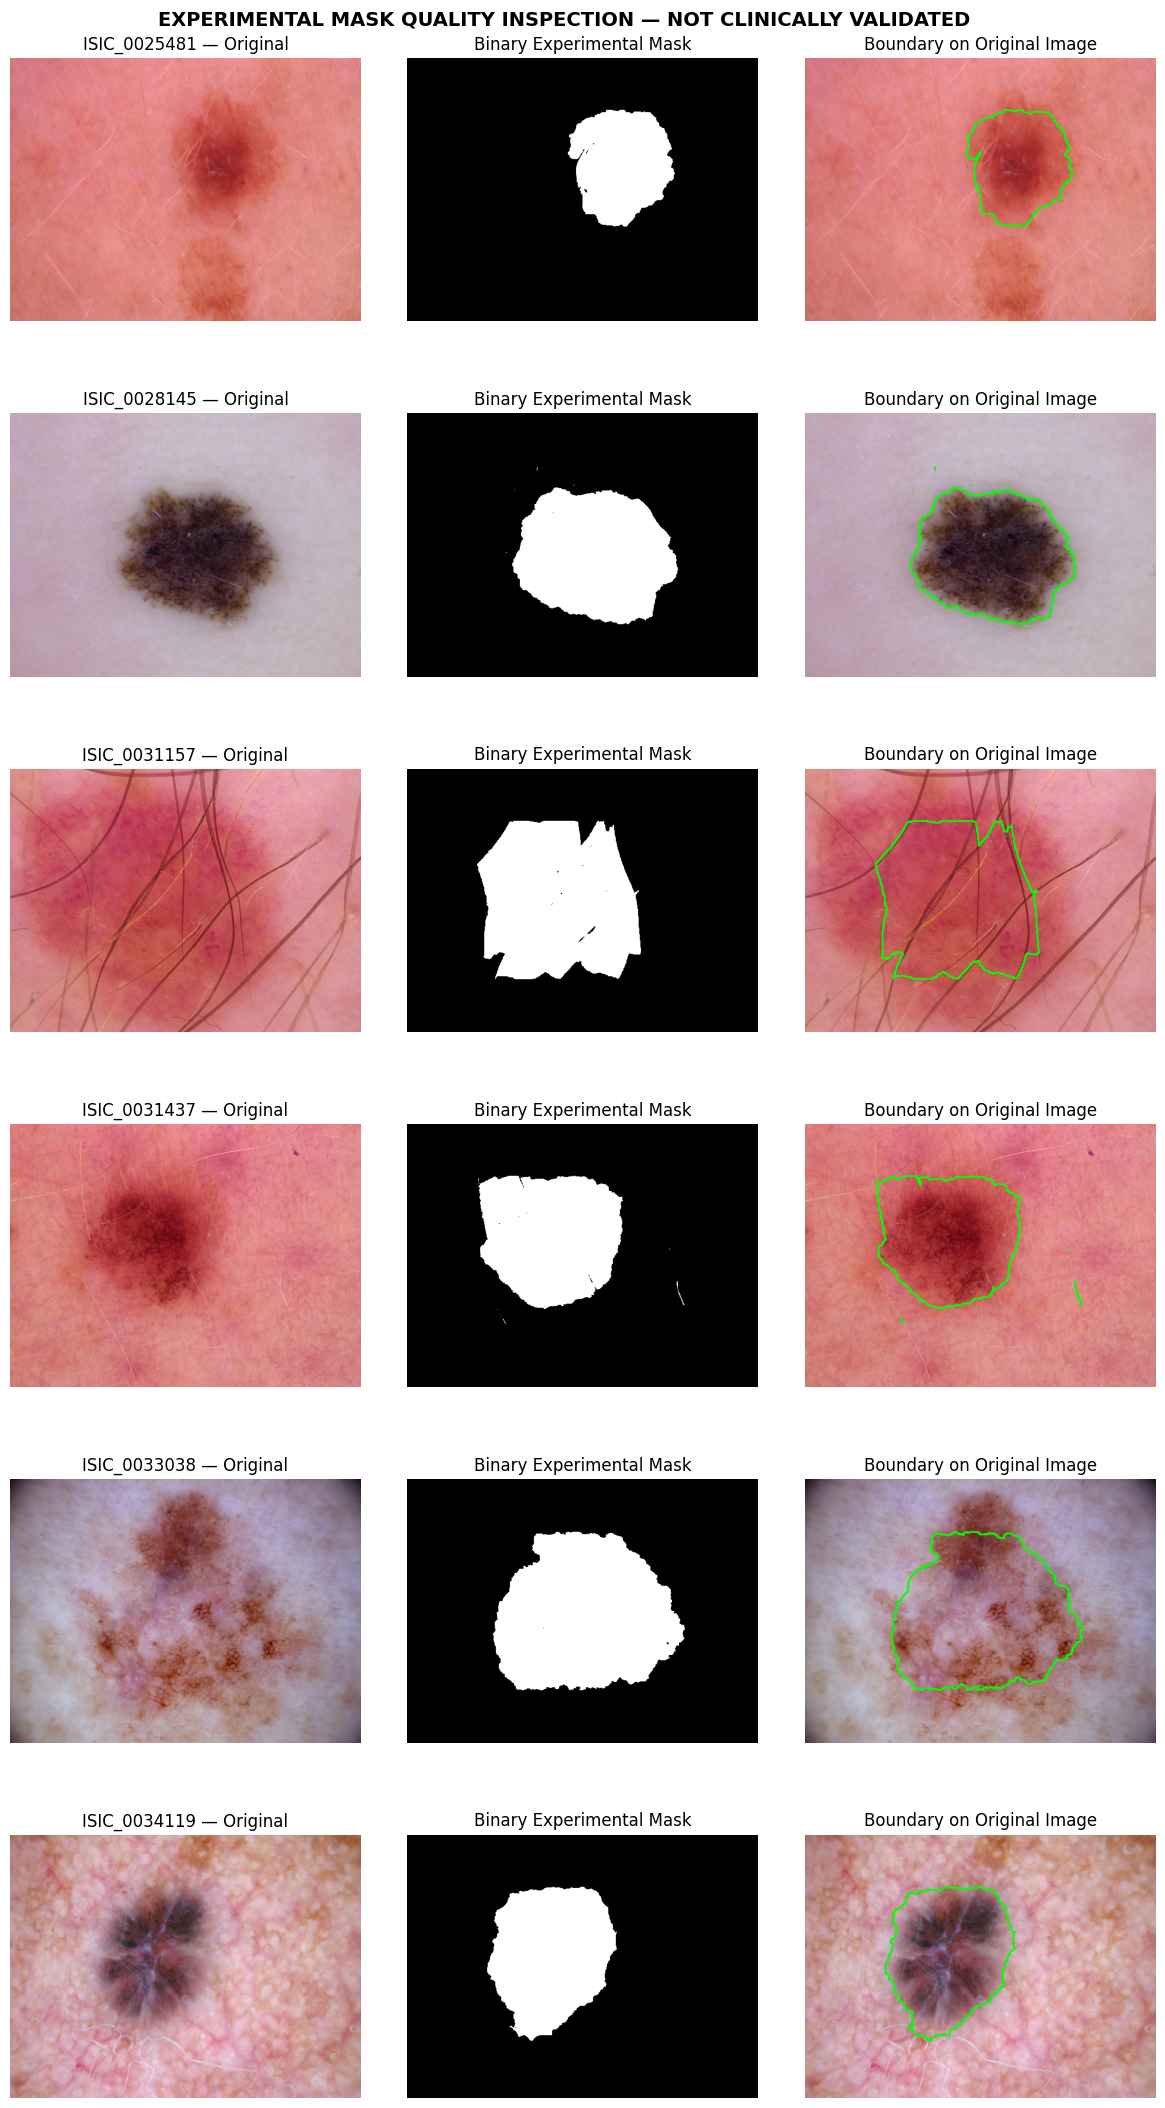


CELL 9 SUMMARY
Masks inspected: 6
QA CSV: /content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/experimental_masks/experimental_mask_quality_control.csv
QA JSON: /content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/experimental_masks/experimental_mask_quality_control.json
Expert reference masks: NOT AVAILABLE
Clinical validation: NOT PERFORMED
Automatic acceptance: DISABLED

SUCCESS: MASK QUALITY-CONTROL AUDIT COMPLETED!


In [ ]:

# ============================================================
# PHASE 10 — CELL 9: EXPERIMENTAL MASK QUALITY-CONTROL AUDIT
# ============================================================

import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

PROJECT_DIR = Path(PROJECT_DIR)

OUTPUT_DIR = (
    PROJECT_DIR
    / "outputs/explainability_evidence/experimental_masks"
)

MASK_DIR = OUTPUT_DIR / "binary_masks"

qa_records = []
qa_images = []

print("=" * 75)
print("EXPERIMENTAL SEGMENTATION QUALITY-CONTROL AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. INSPECT EACH MASK
# ------------------------------------------------------------

for image_id in sorted(reference_ids):

    mask_path = MASK_DIR / f"{image_id}_experimental_mask.png"

    if not mask_path.exists():
        print("MISSING MASK:", image_id)
        continue

    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        print("UNREADABLE MASK:", image_id)
        continue

    height, width = mask.shape
    binary = (mask > 0).astype(np.uint8)

    foreground_pixels = int(binary.sum())
    total_pixels = height * width
    area_fraction = foreground_pixels / total_pixels

    # Connected component analysis
    component_count, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(binary, 8)
    )

    components = stats[1:, cv2.CC_STAT_AREA]
    largest_component = (
        int(components.max()) if len(components) else 0
    )

    small_component_count = int(
        np.sum(components < 100)
    )

    # Largest component proportion
    largest_component_fraction = (
        largest_component / foreground_pixels
        if foreground_pixels else 0
    )

    # Image-border contact
    border_pixels = np.concatenate([
        binary[0, :],
        binary[-1, :],
        binary[:, 0],
        binary[:, -1]
    ])

    border_contact = bool(np.any(border_pixels))

    # Bounding rectangle
    ys, xs = np.where(binary > 0)

    if len(xs):
        x_min, x_max = int(xs.min()), int(xs.max())
        y_min, y_max = int(ys.min()), int(ys.max())

        bbox_fraction = (
            ((x_max - x_min + 1) * (y_max - y_min + 1))
            / total_pixels
        )
    else:
        x_min = x_max = y_min = y_max = None
        bbox_fraction = 0

    # Boundary perimeter and compactness
    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    perimeter = float(
        sum(cv2.arcLength(c, True) for c in contours)
    )

    compactness = (
        (4 * np.pi * foreground_pixels / (perimeter ** 2))
        if perimeter > 0 else 0
    )

    record = {
        "image_id": image_id,
        "width": width,
        "height": height,
        "foreground_pixels": foreground_pixels,
        "area_fraction": round(area_fraction, 6),
        "connected_components": int(component_count - 1),
        "largest_component_fraction": round(
            largest_component_fraction, 6
        ),
        "small_components_below_100_pixels": small_component_count,
        "touches_image_border": border_contact,
        "bounding_box_area_fraction": round(
            bbox_fraction, 6
        ),
        "boundary_perimeter_pixels": round(perimeter, 2),
        "compactness": round(compactness, 6),
        "expert_validation": False
    }

    qa_records.append(record)

    # Load corresponding original image
    image_path = (
        PROJECT_DIR
        / "datasets/training/extracted/Health/training/images"
        / f"{image_id}.jpg"
    )

    image = np.array(Image.open(image_path).convert("RGB"))

    # Draw boundary only for easier inspection
    boundary_image = image.copy()

    boundary_contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        boundary_image,
        boundary_contours,
        -1,
        (0, 255, 0),
        2
    )

    qa_images.append({
        "image_id": image_id,
        "original": image,
        "mask": binary * 255,
        "boundary": boundary_image
    })


# ------------------------------------------------------------
# 2. PRINT QUALITY-CONTROL TABLE
# ------------------------------------------------------------

qa_df = pd.DataFrame(qa_records)

print("\n" + "=" * 75)
print("MASK QUALITY-CONTROL METRICS")
print("=" * 75)

if not qa_df.empty:
    print(qa_df.to_string(index=False))

    qa_csv = OUTPUT_DIR / "experimental_mask_quality_control.csv"
    qa_df.to_csv(qa_csv, index=False)

    print("\nQuality-control CSV saved:", qa_csv)


# ------------------------------------------------------------
# 3. CLEAN VISUAL INSPECTION MONTAGE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BOUNDARY INSPECTION MONTAGE")
print("=" * 75)

if qa_images:

    fig, axes = plt.subplots(
        len(qa_images),
        3,
        figsize=(15, 4 * len(qa_images))
    )

    fig.subplots_adjust(
        top=0.96,
        hspace=0.35,
        wspace=0.08
    )

    for i, item in enumerate(qa_images):

        axes[i, 0].imshow(item["original"])
        axes[i, 0].set_title(
            f'{item["image_id"]} — Original'
        )

        axes[i, 1].imshow(
            item["mask"],
            cmap="gray",
            vmin=0,
            vmax=255
        )
        axes[i, 1].set_title("Binary Experimental Mask")

        axes[i, 2].imshow(item["boundary"])
        axes[i, 2].set_title("Boundary on Original Image")

        for ax in axes[i]:
            ax.axis("off")

    fig.suptitle(
        "EXPERIMENTAL MASK QUALITY INSPECTION — NOT CLINICALLY VALIDATED",
        fontsize=14,
        fontweight="bold"
    )

    plt.show()


# ------------------------------------------------------------
# 4. SAVE MACHINE-READABLE QA RECORD
# ------------------------------------------------------------

qa_json = OUTPUT_DIR / "experimental_mask_quality_control.json"

with open(qa_json, "w", encoding="utf-8") as f:
    json.dump(
        qa_records,
        f,
        indent=2
    )

print("\n" + "=" * 75)
print("CELL 9 SUMMARY")
print("=" * 75)

print("Masks inspected:", len(qa_records))
print("QA CSV:", qa_csv if qa_records else "Not generated")
print("QA JSON:", qa_json)
print("Expert reference masks: NOT AVAILABLE")
print("Clinical validation: NOT PERFORMED")
print("Automatic acceptance: DISABLED")

print("\nSUCCESS: MASK QUALITY-CONTROL AUDIT COMPLETED!")


PHASE 10 — MASK CLEANUP

IMAGE: ISIC_0025481
Raw area fraction: 0.0991
Cleaned area fraction: 0.0991
Removed isolated pixels: 0
Review status: PRELIMINARY_VISUAL_REVIEW_REQUIRED

IMAGE: ISIC_0028145
Raw area fraction: 0.1804
Cleaned area fraction: 0.1803
Removed isolated pixels: 11
Review status: PRELIMINARY_VISUAL_REVIEW_REQUIRED

IMAGE: ISIC_0031157
Raw area fraction: 0.2277
Cleaned area fraction: 0.2277
Removed isolated pixels: 0
Review status: SEGMENTATION_UNSUITABLE_PENDING_REVIEW

IMAGE: ISIC_0031437
Raw area fraction: 0.1664
Cleaned area fraction: 0.1661
Removed isolated pixels: 84
Review status: PRELIMINARY_VISUAL_REVIEW_REQUIRED

IMAGE: ISIC_0033038
Raw area fraction: 0.2477
Cleaned area fraction: 0.2477
Removed isolated pixels: 0
Review status: BOUNDARY_COMPLETENESS_REVIEW_REQUIRED

IMAGE: ISIC_0034119
Raw area fraction: 0.1551
Cleaned area fraction: 0.1551
Removed isolated pixels: 0
Review status: PRELIMINARY_VISUAL_REVIEW_REQUIRED

CLEANED MASK VISUAL INSPECTION


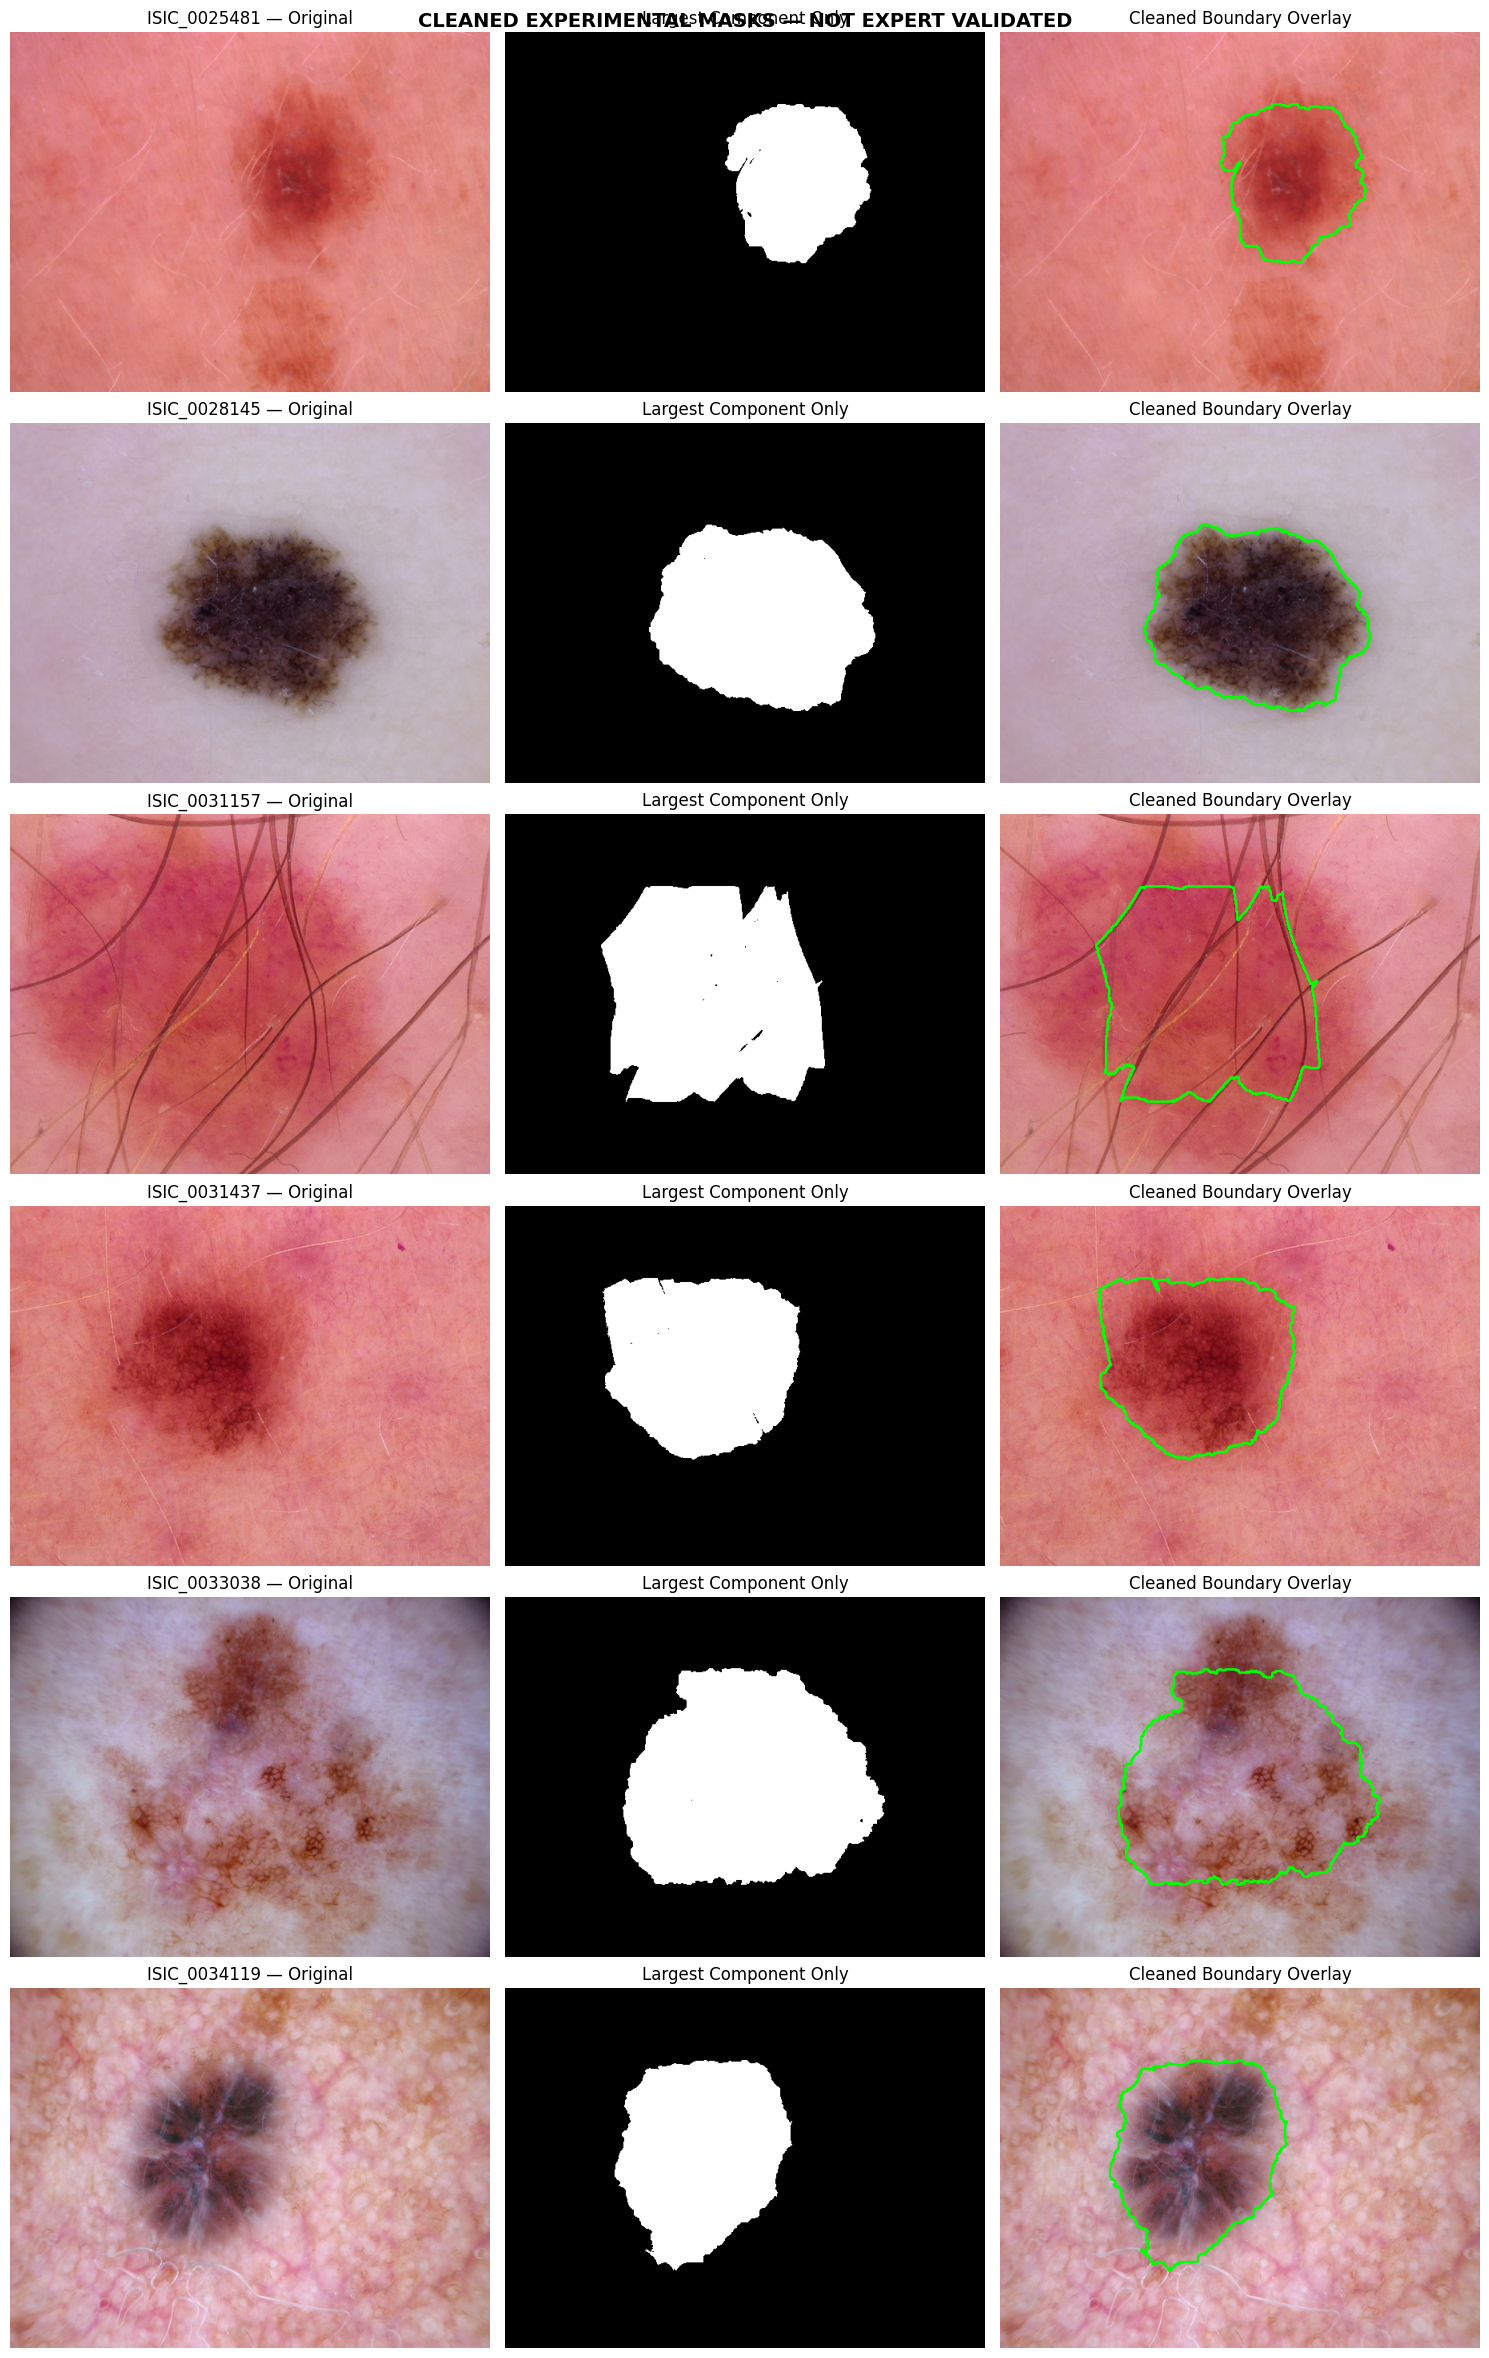


PHASE 10 — CELL 10 SUMMARY
ISIC_0025481 | PRELIMINARY_VISUAL_REVIEW_REQUIRED
ISIC_0028145 | PRELIMINARY_VISUAL_REVIEW_REQUIRED
ISIC_0031157 | SEGMENTATION_UNSUITABLE_PENDING_REVIEW
ISIC_0031437 | PRELIMINARY_VISUAL_REVIEW_REQUIRED
ISIC_0033038 | BOUNDARY_COMPLETENESS_REVIEW_REQUIRED
ISIC_0034119 | PRELIMINARY_VISUAL_REVIEW_REQUIRED

Masks cleaned: 6
Cleanup method: Largest connected component only
Original masks preserved: True
Expert reference masks: NOT AVAILABLE
Clinical validation: NOT PERFORMED
Automatic acceptance: DISABLED

Records JSON: /content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/experimental_masks/mask_cleanup_review_records.json
Summary CSV: /content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/experimental_masks/mask_cleanup_review_summary.csv

SUCCESS: MASK CLEANUP AND REVIEW CLASSIFICATION COMPLETED!


In [ ]:

# ============================================================
# PHASE 10 — CELL 10:
# MASK CLEANUP & VISUAL REVIEW CLASSIFICATION
# ============================================================

import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

PROJECT_DIR = Path(PROJECT_DIR)

BASE_DIR = (
    PROJECT_DIR
    / "outputs/explainability_evidence/experimental_masks"
)

RAW_MASK_DIR = BASE_DIR / "binary_masks"

CLEAN_MASK_DIR = BASE_DIR / "cleaned_masks"
CLEAN_OVERLAY_DIR = BASE_DIR / "cleaned_overlays"

CLEAN_MASK_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_OVERLAY_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_DIR = (
    PROJECT_DIR
    / "datasets/training/extracted/Health/training/images"
)

# Preliminary visual review classifications.
# These are technical review flags, NOT clinical assessments.
review_classifications = {
    "ISIC_0025481": {
        "status": "PRELIMINARY_VISUAL_REVIEW_REQUIRED",
        "reason": "Main region appears reasonably localized."
    },
    "ISIC_0028145": {
        "status": "PRELIMINARY_VISUAL_REVIEW_REQUIRED",
        "reason": "Main region appears localized; small isolated components detected."
    },
    "ISIC_0031157": {
        "status": "SEGMENTATION_UNSUITABLE_PENDING_REVIEW",
        "reason": "Geometric mask includes hairs and does not convincingly establish a lesion boundary."
    },
    "ISIC_0031437": {
        "status": "PRELIMINARY_VISUAL_REVIEW_REQUIRED",
        "reason": "Main region appears localized; small isolated components detected."
    },
    "ISIC_0033038": {
        "status": "BOUNDARY_COMPLETENESS_REVIEW_REQUIRED",
        "reason": "Potential omission of visible pigmented structures."
    },
    "ISIC_0034119": {
        "status": "PRELIMINARY_VISUAL_REVIEW_REQUIRED",
        "reason": "Main region appears localized; completeness requires review."
    }
}

cleaning_records = []
display_items = []

print("=" * 75)
print("PHASE 10 — MASK CLEANUP")
print("=" * 75)

# ------------------------------------------------------------
# 1. CLEAN EACH MASK
# ------------------------------------------------------------

for image_id in sorted(reference_ids):

    raw_mask_path = (
        RAW_MASK_DIR / f"{image_id}_experimental_mask.png"
    )

    image_path = IMAGE_DIR / f"{image_id}.jpg"

    if not raw_mask_path.exists() or not image_path.exists():
        print("MISSING INPUT:", image_id)
        continue

    raw_mask = cv2.imread(
        str(raw_mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    image = np.array(
        Image.open(image_path).convert("RGB")
    )

    if raw_mask is None:
        print("UNREADABLE MASK:", image_id)
        continue

    binary = (raw_mask > 0).astype(np.uint8)

    # Find connected components
    count, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(binary, 8)
    )

    if count <= 1:
        print("EMPTY MASK:", image_id)
        continue

    # Keep only the largest foreground component
    component_areas = stats[1:, cv2.CC_STAT_AREA]
    largest_label = 1 + int(np.argmax(component_areas))

    cleaned_mask = np.where(
        labels == largest_label,
        255,
        0
    ).astype(np.uint8)

    raw_area = int(np.count_nonzero(binary))
    cleaned_area = int(np.count_nonzero(cleaned_mask))

    removed_pixels = raw_area - cleaned_area

    total_pixels = cleaned_mask.size

    raw_fraction = raw_area / total_pixels
    cleaned_fraction = cleaned_area / total_pixels

    # Save cleaned mask separately
    clean_mask_path = (
        CLEAN_MASK_DIR
        / f"{image_id}_cleaned_experimental_mask.png"
    )

    cv2.imwrite(
        str(clean_mask_path),
        cleaned_mask
    )

    # Generate boundary-only overlay
    contours, _ = cv2.findContours(
        (cleaned_mask > 0).astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    boundary_image = image.copy()

    cv2.drawContours(
        boundary_image,
        contours,
        -1,
        (0, 255, 0),
        2
    )

    clean_overlay_path = (
        CLEAN_OVERLAY_DIR
        / f"{image_id}_cleaned_boundary_overlay.png"
    )

    Image.fromarray(boundary_image).save(
        clean_overlay_path
    )

    review = review_classifications[image_id]

    record = {
        "image_id": image_id,
        "raw_mask_path": str(raw_mask_path),
        "cleaned_mask_path": str(clean_mask_path),
        "cleaned_overlay_path": str(clean_overlay_path),
        "cleanup_method": "LARGEST_CONNECTED_COMPONENT_ONLY",
        "raw_foreground_pixels": raw_area,
        "cleaned_foreground_pixels": cleaned_area,
        "removed_pixels": removed_pixels,
        "raw_area_fraction": round(raw_fraction, 6),
        "cleaned_area_fraction": round(cleaned_fraction, 6),
        "preliminary_visual_review_status": review["status"],
        "preliminary_visual_review_reason": review["reason"],
        "expert_annotation": False,
        "clinical_validation": "NOT_PERFORMED",
        "automatic_acceptance": False,
        "clinical_interpretation": None
    }

    cleaning_records.append(record)

    display_items.append({
        "image_id": image_id,
        "original": image,
        "cleaned_mask": cleaned_mask,
        "boundary": boundary_image
    })

    print("\nIMAGE:", image_id)
    print("Raw area fraction:", round(raw_fraction, 4))
    print("Cleaned area fraction:", round(cleaned_fraction, 4))
    print("Removed isolated pixels:", removed_pixels)
    print("Review status:", review["status"])


# ------------------------------------------------------------
# 2. SAVE CLEANUP RECORDS
# ------------------------------------------------------------

records_path = (
    BASE_DIR / "mask_cleanup_review_records.json"
)

with open(records_path, "w", encoding="utf-8") as f:
    json.dump(cleaning_records, f, indent=2)

summary_path = (
    BASE_DIR / "mask_cleanup_review_summary.csv"
)

pd.DataFrame(cleaning_records).to_csv(
    summary_path,
    index=False
)


# ------------------------------------------------------------
# 3. DISPLAY CLEANED MASKS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLEANED MASK VISUAL INSPECTION")
print("=" * 75)

if display_items:

    fig, axes = plt.subplots(
        len(display_items),
        3,
        figsize=(15, 4 * len(display_items))
    )

    for i, item in enumerate(display_items):

        axes[i, 0].imshow(item["original"])
        axes[i, 0].set_title(
            f'{item["image_id"]} — Original'
        )

        axes[i, 1].imshow(
            item["cleaned_mask"],
            cmap="gray",
            vmin=0,
            vmax=255
        )
        axes[i, 1].set_title("Largest Component Only")

        axes[i, 2].imshow(item["boundary"])
        axes[i, 2].set_title("Cleaned Boundary Overlay")

        for ax in axes[i]:
            ax.axis("off")

    fig.suptitle(
        "CLEANED EXPERIMENTAL MASKS — NOT EXPERT VALIDATED",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 4. REVIEW STATUS SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 10 — CELL 10 SUMMARY")
print("=" * 75)

for record in cleaning_records:
    print(
        record["image_id"],
        "|",
        record["preliminary_visual_review_status"]
    )

print("\nMasks cleaned:", len(cleaning_records))
print("Cleanup method: Largest connected component only")
print("Original masks preserved:", True)
print("Expert reference masks: NOT AVAILABLE")
print("Clinical validation: NOT PERFORMED")
print("Automatic acceptance: DISABLED")

print("\nRecords JSON:", records_path)
print("Summary CSV:", summary_path)
print("\nSUCCESS: MASK CLEANUP AND REVIEW CLASSIFICATION COMPLETED!")


In [ ]:

# ============================================================
# PHASE 10 — CELL 11:
# VISUAL EVIDENCE INTEGRATION & TRACEABILITY
# ============================================================

import json
import pandas as pd

from pathlib import Path

PROJECT_DIR = Path(PROJECT_DIR)

BASE_DIR = (
    PROJECT_DIR
    / "outputs/explainability_evidence"
)

MASK_BASE = BASE_DIR / "experimental_masks"

RAW_MASK_DIR = MASK_BASE / "binary_masks"
CLEAN_MASK_DIR = MASK_BASE / "cleaned_masks"
OVERLAY_DIR = MASK_BASE / "visual_overlays"
CLEAN_OVERLAY_DIR = MASK_BASE / "cleaned_overlays"

IMAGE_DIR = (
    PROJECT_DIR
    / "datasets/training/extracted/Health/training/images"
)

# ------------------------------------------------------------
# 1. REVIEW CLASSIFICATION
# ------------------------------------------------------------

review_classifications = {
    "ISIC_0025481": {
        "status": "PRELIMINARY_VISUAL_REVIEW_REQUIRED",
        "suitability": "PROVISIONALLY_LOCALIZED",
        "reason": "Boundary appears reasonably localized; expert verification remains outstanding."
    },
    "ISIC_0028145": {
        "status": "PRELIMINARY_VISUAL_REVIEW_REQUIRED",
        "suitability": "PROVISIONALLY_LOCALIZED",
        "reason": "Main region appears localized; small disconnected components were removed."
    },
    "ISIC_0031157": {
        "status": "SEGMENTATION_UNSUITABLE_PENDING_REVIEW",
        "suitability": "UNSUITABLE_FOR_CURRENT_VISUAL_EXPLANATION",
        "reason": "Geometric mask includes hairs and does not convincingly establish a lesion boundary."
    },
    "ISIC_0031437": {
        "status": "PRELIMINARY_VISUAL_REVIEW_REQUIRED",
        "suitability": "PROVISIONALLY_LOCALIZED",
        "reason": "Main region appears localized; small disconnected components were removed."
    },
    "ISIC_0033038": {
        "status": "BOUNDARY_COMPLETENESS_REVIEW_REQUIRED",
        "suitability": "BOUNDARY_COMPLETENESS_UNCERTAIN",
        "reason": "Mask covers a broad region containing multiple visible pigmented structures; completeness is uncertain."
    },
    "ISIC_0034119": {
        "status": "PRELIMINARY_VISUAL_REVIEW_REQUIRED",
        "suitability": "PROVISIONALLY_LOCALIZED",
        "reason": "Boundary appears reasonably localized; completeness and accuracy remain unverified."
    }
}

# ------------------------------------------------------------
# 2. LOAD QUALITY-CONTROL AND CLEANUP RECORDS
# ------------------------------------------------------------

qa_path = (
    MASK_BASE / "experimental_mask_quality_control.json"
)

cleanup_path = (
    MASK_BASE / "mask_cleanup_review_records.json"
)

with open(qa_path, "r", encoding="utf-8") as f:
    qa_records = json.load(f)

with open(cleanup_path, "r", encoding="utf-8") as f:
    cleanup_records = json.load(f)

qa_by_id = {
    record["image_id"]: record
    for record in qa_records
}

cleanup_by_id = {
    record["image_id"]: record
    for record in cleanup_records
}

# ------------------------------------------------------------
# 3. BUILD VISUAL EVIDENCE INDEX
# ------------------------------------------------------------

visual_evidence_records = []

print("=" * 75)
print("VISUAL EVIDENCE INTEGRATION")
print("=" * 75)

for image_id in sorted(reference_ids):

    source_image = IMAGE_DIR / f"{image_id}.jpg"

    raw_mask = (
        RAW_MASK_DIR
        / f"{image_id}_experimental_mask.png"
    )

    cleaned_mask = (
        CLEAN_MASK_DIR
        / f"{image_id}_cleaned_experimental_mask.png"
    )

    raw_overlay = (
        OVERLAY_DIR
        / f"{image_id}_experimental_overlay.png"
    )

    cleaned_overlay = (
        CLEAN_OVERLAY_DIR
        / f"{image_id}_cleaned_boundary_overlay.png"
    )

    required_paths = [
        source_image,
        raw_mask,
        cleaned_mask,
        raw_overlay,
        cleaned_overlay
    ]

    missing_artifacts = [
        str(path)
        for path in required_paths
        if not path.exists()
    ]

    qa = qa_by_id.get(image_id, {})
    cleanup = cleanup_by_id.get(image_id, {})
    review = review_classifications[image_id]

    record = {
        "image_id": image_id,

        "source_image": str(source_image),
        "original_experimental_mask": str(raw_mask),
        "cleaned_experimental_mask": str(cleaned_mask),
        "original_overlay": str(raw_overlay),
        "cleaned_boundary_overlay": str(cleaned_overlay),

        "visualization_method": "OPENCV_GRABCUT_EXPERIMENTAL_V1",
        "cleanup_method": "LARGEST_CONNECTED_COMPONENT_ONLY",

        "generated_area_fraction": qa.get("area_fraction"),
        "cleaned_area_fraction": cleanup.get("cleaned_area_fraction"),

        "connected_components_before_cleanup": (
            qa.get("connected_components")
        ),

        "removed_pixels_during_cleanup": (
            cleanup.get("removed_pixels")
        ),

        "visual_review_status": review["status"],
        "segmentation_suitability": review["suitability"],
        "visual_review_reason": review["reason"],

        "artifact_completeness": (
            "COMPLETE" if not missing_artifacts else "INCOMPLETE"
        ),

        "missing_artifacts": missing_artifacts,

        "mask_provenance": "REGENERATED_EXPERIMENTAL",
        "expert_reference_mask_available": False,
        "expert_annotation_verified": False,
        "clinical_validation": "NOT_PERFORMED",
        "diagnostic_interpretation": None,
        "automatic_acceptance": False,
        "mandatory_human_review": True,

        "limitations": [
            "Original Phase 5 segmentation source code was not recovered.",
            "Mask generated using a new experimental GrabCut configuration.",
            "No expert reference segmentation mask was identified.",
            "Cleanup does not establish segmentation accuracy.",
            "Area comparison does not establish boundary equivalence.",
            "Visual overlay is not a diagnostic or clinical explanation."
        ]
    }

    visual_evidence_records.append(record)

    print(
        image_id,
        "|",
        record["artifact_completeness"],
        "|",
        record["visual_review_status"]
    )


# ------------------------------------------------------------
# 4. SAVE VISUAL EVIDENCE INDEX
# ------------------------------------------------------------

index_path = (
    BASE_DIR / "visual_explainability_evidence_index.json"
)

with open(index_path, "w", encoding="utf-8") as f:
    json.dump(
        visual_evidence_records,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 5. SAVE VISUAL TRACEABILITY MATRIX
# ------------------------------------------------------------

traceability_rows = []

for record in visual_evidence_records:

    traceability_rows.append({
        "image_id": record["image_id"],
        "source_image": record["source_image"],
        "experimental_mask": record["original_experimental_mask"],
        "cleaned_mask": record["cleaned_experimental_mask"],
        "experimental_overlay": record["original_overlay"],
        "cleaned_overlay": record["cleaned_boundary_overlay"],
        "mask_provenance": record["mask_provenance"],
        "artifact_completeness": record["artifact_completeness"],
        "visual_review_status": record["visual_review_status"],
        "segmentation_suitability": record["segmentation_suitability"],
        "expert_reference_available": False,
        "clinical_validation": "NOT_PERFORMED",
        "human_review_required": True
    })

traceability_df = pd.DataFrame(traceability_rows)

traceability_path = (
    BASE_DIR / "visual_evidence_traceability_matrix.csv"
)

traceability_df.to_csv(
    traceability_path,
    index=False
)

# ------------------------------------------------------------
# 6. SAVE CLINICIAN-READABLE VISUAL REVIEW ADDENDUM
# ------------------------------------------------------------

clinician_addendum = {
    "agent": "Veloura Explainability & Evidence Agent",
    "section": "Experimental Visual Evidence Addendum",
    "status": "EXPERIMENTAL_VISUALIZATION_ONLY",
    "cases": visual_evidence_records,
    "global_limitations": [
        "No expert reference masks available.",
        "No clinical segmentation validation performed.",
        "No Dice or IoU scores can be reported.",
        "Visual review statuses are preliminary technical observations.",
        "All cases require qualified human review.",
        "No independent diagnosis or automatic clinical acceptance is permitted."
    ]
}

addendum_path = (
    BASE_DIR / "clinician_visual_evidence_addendum.json"
)

with open(addendum_path, "w", encoding="utf-8") as f:
    json.dump(
        clinician_addendum,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

complete_count = sum(
    record["artifact_completeness"] == "COMPLETE"
    for record in visual_evidence_records
)

unsuitable_count = sum(
    record["segmentation_suitability"]
    == "UNSUITABLE_FOR_CURRENT_VISUAL_EXPLANATION"
    for record in visual_evidence_records
)

print("\n" + "=" * 75)
print("CELL 11 SUMMARY")
print("=" * 75)

print("Cases indexed:", len(visual_evidence_records))
print("Complete visual artifact sets:", complete_count)
print("Cases flagged unsuitable:", unsuitable_count)
print("Expert masks available:", False)
print("Clinical validation:", "NOT PERFORMED")
print("Automatic acceptance:", False)
print("Human review required:", True)

print("\nGenerated files:")
print(index_path)
print(traceability_path)
print(addendum_path)

print("\nSUCCESS: VISUAL EVIDENCE INTEGRATION COMPLETED!")


VISUAL EVIDENCE INTEGRATION
ISIC_0025481 | COMPLETE | PRELIMINARY_VISUAL_REVIEW_REQUIRED
ISIC_0028145 | COMPLETE | PRELIMINARY_VISUAL_REVIEW_REQUIRED
ISIC_0031157 | COMPLETE | SEGMENTATION_UNSUITABLE_PENDING_REVIEW
ISIC_0031437 | COMPLETE | PRELIMINARY_VISUAL_REVIEW_REQUIRED
ISIC_0033038 | COMPLETE | BOUNDARY_COMPLETENESS_REVIEW_REQUIRED
ISIC_0034119 | COMPLETE | PRELIMINARY_VISUAL_REVIEW_REQUIRED

CELL 11 SUMMARY
Cases indexed: 6
Complete visual artifact sets: 6
Cases flagged unsuitable: 1
Expert masks available: False
Clinical validation: NOT PERFORMED
Automatic acceptance: False
Human review required: True

Generated files:
/content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/visual_explainability_evidence_index.json
/content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/visual_evidence_traceability_matrix.csv
/content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/clinician_visual_evidence_addendum.json

SUCCE

In [ ]:

# ============================================================
# PHASE 10 — CELL 12:
# FINAL VERIFICATION & COMPLETION AUDIT
# ============================================================

import json
import pandas as pd
import cv2
import numpy as np

from pathlib import Path

PROJECT_DIR = Path(PROJECT_DIR)

BASE_DIR = PROJECT_DIR / "outputs"
REPORT_DIR = PROJECT_DIR / "reports"

EXPLAIN_DIR = BASE_DIR / "explainability_evidence"
REPORT_EXPLAIN_DIR = REPORT_DIR / "explainability_evidence"

MASK_BASE = EXPLAIN_DIR / "experimental_masks"

target_ids = sorted(reference_ids)

checks = []

# ------------------------------------------------------------
# HELPER FUNCTIONS
# ------------------------------------------------------------

def record_check(name, condition, details=""):
    checks.append({
        "check": name,
        "status": "PASS" if condition else "FAIL",
        "details": details
    })


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def contains_all_target_ids(data):
    text = json.dumps(data)
    return all(image_id in text for image_id in target_ids)


print("=" * 75)
print("VELOURA — PHASE 10 FINAL VERIFICATION")
print("=" * 75)


# ------------------------------------------------------------
# 1. CORE EXPLAINABILITY OUTPUTS
# ------------------------------------------------------------

core_json_files = {
    "Explainability logs":
        EXPLAIN_DIR / "explainability_evidence_sample_logs.json",

    "Clinician-readable summaries":
        EXPLAIN_DIR / "clinician_readable_case_summaries.json",

    "Visual evidence index":
        EXPLAIN_DIR / "visual_explainability_evidence_index.json",

    "Visual evidence addendum":
        EXPLAIN_DIR / "clinician_visual_evidence_addendum.json",

    "Experimental segmentation records":
        MASK_BASE / "experimental_segmentation_records.json",

    "Mask cleanup records":
        MASK_BASE / "mask_cleanup_review_records.json",

    "Mask quality-control records":
        MASK_BASE / "experimental_mask_quality_control.json"
}

loaded_data = {}

print("\n1. CORE EXPLAINABILITY FILES")

for name, path in core_json_files.items():

    exists = path.exists()

    record_check(
        f"{name} file exists",
        exists,
        str(path)
    )

    if exists:
        try:
            loaded_data[name] = load_json(path)

            record_check(
                f"{name} valid JSON",
                True
            )

            record_check(
                f"{name} contains all six image IDs",
                contains_all_target_ids(loaded_data[name])
            )

        except Exception as e:
            record_check(
                f"{name} valid JSON",
                False,
                repr(e)
            )


# ------------------------------------------------------------
# 2. VISUAL ARTIFACT INTEGRITY
# ------------------------------------------------------------

print("\n2. VISUAL ARTIFACT INTEGRITY")

IMAGE_DIR = (
    PROJECT_DIR
    / "datasets/training/extracted/Health/training/images"
)

RAW_MASK_DIR = MASK_BASE / "binary_masks"
CLEAN_MASK_DIR = MASK_BASE / "cleaned_masks"
RAW_OVERLAY_DIR = MASK_BASE / "visual_overlays"
CLEAN_OVERLAY_DIR = MASK_BASE / "cleaned_overlays"

artifact_count = 0
mask_integrity_count = 0

for image_id in target_ids:

    artifact_paths = [
        IMAGE_DIR / f"{image_id}.jpg",

        RAW_MASK_DIR /
        f"{image_id}_experimental_mask.png",

        CLEAN_MASK_DIR /
        f"{image_id}_cleaned_experimental_mask.png",

        RAW_OVERLAY_DIR /
        f"{image_id}_experimental_overlay.png",

        CLEAN_OVERLAY_DIR /
        f"{image_id}_cleaned_boundary_overlay.png"
    ]

    all_exist = all(
        path.exists() for path in artifact_paths
    )

    record_check(
        f"{image_id} five visual artifacts exist",
        all_exist
    )

    if all_exist:
        artifact_count += 1

        original = cv2.imread(str(artifact_paths[0]))
        raw_mask = cv2.imread(
            str(artifact_paths[1]),
            cv2.IMREAD_GRAYSCALE
        )
        clean_mask = cv2.imread(
            str(artifact_paths[2]),
            cv2.IMREAD_GRAYSCALE
        )

        dimensions_match = (
            original is not None
            and raw_mask is not None
            and clean_mask is not None
            and original.shape[:2] == raw_mask.shape
            and original.shape[:2] == clean_mask.shape
        )

        record_check(
            f"{image_id} image and mask dimensions match",
            dimensions_match
        )

        binary_values_valid = (
            raw_mask is not None
            and clean_mask is not None
            and set(
                int(v) for v in np.unique(raw_mask)
            ).issubset({0, 255})
            and set(
                int(v) for v in np.unique(clean_mask)
            ).issubset({0, 255})
        )

        record_check(
            f"{image_id} masks are binary",
            binary_values_valid
        )

        if dimensions_match and binary_values_valid:
            mask_integrity_count += 1


# ------------------------------------------------------------
# 3. VISUAL EVIDENCE INDEX AND TRACEABILITY
# ------------------------------------------------------------

print("\n3. VISUAL EVIDENCE TRACEABILITY")

index_path = (
    EXPLAIN_DIR / "visual_explainability_evidence_index.json"
)

traceability_path = (
    EXPLAIN_DIR / "visual_evidence_traceability_matrix.csv"
)

visual_index = []

if index_path.exists():

    visual_index = load_json(index_path)

    record_check(
        "Visual index has six records",
        len(visual_index) == 6,
        f"Records: {len(visual_index)}"
    )

    index_ids = {
        record.get("image_id")
        for record in visual_index
    }

    record_check(
        "Visual index image IDs match",
        index_ids == set(target_ids)
    )

    complete_records = [
        record for record in visual_index
        if record.get("artifact_completeness") == "COMPLETE"
    ]

    record_check(
        "All six visual artifact sets complete",
        len(complete_records) == 6
    )

    record_check(
        "All records preserve experimental provenance",
        all(
            record.get("mask_provenance")
            == "REGENERATED_EXPERIMENTAL"
            for record in visual_index
        )
    )

    record_check(
        "Expert reference masks not falsely claimed",
        all(
            record.get("expert_reference_mask_available")
            is False
            for record in visual_index
        )
    )

if traceability_path.exists():

    traceability_df = pd.read_csv(traceability_path)

    record_check(
        "Visual traceability CSV has six rows",
        len(traceability_df) == 6,
        f"Rows: {len(traceability_df)}"
    )

    record_check(
        "All six image IDs appear in traceability CSV",
        set(traceability_df["image_id"]) == set(target_ids)
    )

else:
    record_check(
        "Visual traceability CSV exists",
        False
    )


# ------------------------------------------------------------
# 4. UPSTREAM AGENT EVIDENCE
# FIXED: THESE FILES ARE IN reports/, NOT outputs/
# ------------------------------------------------------------

print("\n4. UPSTREAM AGENT EVIDENCE")

provenance_path = (
    REPORT_EXPLAIN_DIR / "evidence_traceability_matrix.csv"
)

summary_path = (
    REPORT_EXPLAIN_DIR / "clinician_case_summary.csv"
)

# Original evidence traceability
if provenance_path.exists():

    provenance_df = pd.read_csv(provenance_path)

    record_check(
        "Original evidence traceability has 36 entries",
        len(provenance_df) == 36,
        f"Entries: {len(provenance_df)}"
    )

    if "image_id" in provenance_df.columns:
        record_check(
            "Original evidence traceability covers six images",
            set(provenance_df["image_id"]) == set(target_ids)
        )
    else:
        record_check(
            "Original evidence traceability has image_id column",
            False
        )

else:
    record_check(
        "Original evidence traceability exists",
        False,
        str(provenance_path)
    )


# Clinician-readable case summary
if summary_path.exists():

    summary_df = pd.read_csv(summary_path)

    record_check(
        "Clinician case summary has six cases",
        len(summary_df) == 6,
        f"Rows: {len(summary_df)}"
    )

    possible_id_columns = [
        col for col in summary_df.columns
        if col.lower() in ["image_id", "case_id"]
    ]

    if possible_id_columns:
        id_column = possible_id_columns[0]

        record_check(
            "Clinician case summary covers six images",
            set(summary_df[id_column].astype(str))
            == set(target_ids)
        )

else:
    record_check(
        "Clinician case summary exists",
        False,
        str(summary_path)
    )


# ------------------------------------------------------------
# 5. SAFETY AND CLINICAL LIMITATION CHECKS
# ------------------------------------------------------------

print("\n5. SAFETY AND CLINICAL LIMITATIONS")

if visual_index:

    record_check(
        "Clinical validation remains unperformed",
        all(
            record.get("clinical_validation")
            == "NOT_PERFORMED"
            for record in visual_index
        )
    )

    record_check(
        "Automatic acceptance disabled",
        all(
            record.get("automatic_acceptance") is False
            for record in visual_index
        )
    )

    record_check(
        "Human review mandatory",
        all(
            record.get("mandatory_human_review") is True
            for record in visual_index
        )
    )

    record_check(
        "No diagnostic interpretation generated",
        all(
            record.get("diagnostic_interpretation") is None
            for record in visual_index
        )
    )

    unsuitable_cases = [
        record["image_id"]
        for record in visual_index
        if record.get("segmentation_suitability")
        == "UNSUITABLE_FOR_CURRENT_VISUAL_EXPLANATION"
    ]

    record_check(
        "ISIC_0031157 remains flagged unsuitable",
        "ISIC_0031157" in unsuitable_cases
    )

    record_check(
        "Exactly one case flagged unsuitable",
        len(unsuitable_cases) == 1,
        str(unsuitable_cases)
    )


# ------------------------------------------------------------
# 6. FINAL VERIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL VERIFICATION RESULTS")
print("=" * 75)

checks_df = pd.DataFrame(checks)

print(checks_df.to_string(index=False))

passed = sum(
    item["status"] == "PASS"
    for item in checks
)

failed = sum(
    item["status"] == "FAIL"
    for item in checks
)

verification_path = (
    REPORT_EXPLAIN_DIR / "phase10_final_verification.csv"
)

verification_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

checks_df.to_csv(
    verification_path,
    index=False
)


# ------------------------------------------------------------
# 7. PHASE 10 STATUS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PHASE 10 COMPLETION STATUS")
print("=" * 75)

print("Total verification checks:", len(checks))
print("Passed:", passed)
print("Failed:", failed)

print(
    "Visual artifact sets complete:",
    artifact_count,
    "/ 6"
)

print(
    "Masks passing integrity checks:",
    mask_integrity_count,
    "/ 6"
)

print("Expert reference masks: NOT AVAILABLE")
print("Clinical validation: NOT PERFORMED")
print("Automatic acceptance: DISABLED")
print("Mandatory human review: ENABLED")

if failed == 0:

    print("\nPHASE 10 TECHNICAL VERIFICATION: PASSED")
    print("PHASE 10 STATUS: IMPLEMENTED AND TECHNICALLY VERIFIED")
    print("CLINICAL VALIDATION STATUS: OUTSTANDING")

else:

    print("\nPHASE 10 TECHNICAL VERIFICATION: FAILED")
    print("Review failed checks before declaring completion.")

print("\nVerification report:", verification_path)
print("\nSUCCESS: FINAL VERIFICATION AUDIT EXECUTED!")


VELOURA — PHASE 10 FINAL VERIFICATION

1. CORE EXPLAINABILITY FILES

2. VISUAL ARTIFACT INTEGRITY

3. VISUAL EVIDENCE TRACEABILITY

4. UPSTREAM AGENT EVIDENCE

5. SAFETY AND CLINICAL LIMITATIONS

FINAL VERIFICATION RESULTS
                                                       check status                                                                                                                                  details
                             Explainability logs file exists   PASS                  /content/drive_phase10/MyDrive/Veloura_Project/outputs/explainability_evidence/explainability_evidence_sample_logs.json
                              Explainability logs valid JSON   PASS                                                                                                                                         
              Explainability logs contains all six image IDs   PASS                                                                                               